# Multichannel sparse blind deconvolution of seismic data

A seismic trace is the Earth's **reflectivity** (sharp changes in rock impedance) blurred by
a **wavelet** (the source pulse after it has travelled through the Earth and the recording
system). Deconvolution tries to undo the blur. In the *blind* version the wavelet is unknown
too, so both have to be recovered from the traces alone.

This notebook builds a sparse blind deconvolution method from first principles, tests it
against classical baselines on data with a known answer, and then applies it to a real
seismic line with a well that gives an independent check.

**Link to the rainfall notebook.** This is the same model as DUNL on rainfall and runoff:

| DUNL on rainfall and runoff | here |
|---|---|
| trial (30-day window) | trace |
| streamflow $y$ | seismic amplitude $y$ |
| effective rain (sparse code) $x$ | reflectivity $r$ |
| unit hydrograph (kernel) $h$ | wavelet $w$ |
| known support (rainy hours) | **none**: support is unknown |
| shift gauge | shift **and phase** gauge |

**Plan**
1. Setup and data
2. The problem
3. Why it is hard (five short demos)
4. Exploratory data analysis: real reflectivity, a 2D model, a field line
5. First-principles design of the solver
6. Baselines
7. Experiments with a known answer
8. Field data: Penobscot line with the L-30 well
9. Summary

**Notation.** $J$ traces, $T$ time samples per trace, wavelet length $L$ (odd, time zero at the
centre sample), sample interval $\Delta t = 4$ ms. $*$ is convolution, $\star$ is correlation.

## 1. Setup

All data come from public GitHub repositories. Each URL is pinned to one commit, and the
SHA-256 of each file is checked, so the inputs never change under us.

| file | what it is | source |
|---|---|---|
| `L-30.las` | sonic and density logs, well L-30, Penobscot (offshore Nova Scotia) | SEG tutorials 2014 |
| `PenobXL_1155.txt` | 401 traces of Penobscot crossline 1155, 4 s at 4 ms | SEG tutorials 2014 |
| `P-129_out.LAS` | sonic and density, well P-129 (offshore Nova Scotia) | `welly` test data |
| `F0*-*_logs.las` | sonic and density, four wells in the F3 block (Dutch North Sea) | SEG tutorials 2017 |
| `poststack_model.npz` | 2D acoustic impedance model | PyLops test data |

**Data terms.** The Penobscot seismic is owned by the Nova Scotia Department of Energy and
distributed by permission through dGB's Open Seismic Repository; the L-30 log was digitized by
Neil Watson (Atlantic Petrophysics) and shared for non-commercial use. See the tutorial
repositories for the full terms of each file.

In [1]:
import os, json, hashlib, time, subprocess, sys, urllib.request, warnings
import importlib.util
for pkg in ["lasio"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, linalg, stats, ndimage
import lasio

warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)

DT = 0.004          # sample interval (s)
L = 81              # wavelet length in samples (320 ms), time zero at index L // 2
SNR_DB = 10         # default noise level for synthetic tests
FIG, DATA, RES = "figures", "data", "results"
for d in (FIG, DATA, RES):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
COL = {"truth": "#222222", "oracle": "#9a9a9a", "B1": "#3b82c4", "B2": "#5aa65a",
       "B3": "#e39b2d", "B4": "#9b6cc4", "AM": "#d64532", "AM-amp": "#7a1f14", "well": "#111111"}
NAMES = {"B1": "B1 zero-phase", "B2": "B2 minimum-phase", "B3": "B3 kurtosis phase",
         "B4": "B4 homomorphic", "AM": "AM sparse (ours)", "AM-amp": "AM sparse + amp. constraint (ours)"}

def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=130, bbox_inches="tight")

In [2]:
SOURCES = {
    "L-30.las": ("seg/tutorials-2014", "aab1cf917bc4b223e1061d2984aa1bce4bc41a1c",
                 "1406_Make_a_synthetic/L-30.las", "daa19bb3a1841d871eeb7cef299ee5e1d742630141708182c6b8cb13669be19c"),
    "PenobXL_1155.txt": ("seg/tutorials-2014", "aab1cf917bc4b223e1061d2984aa1bce4bc41a1c",
                         "1406_Make_a_synthetic/PenobXL_1155.txt", "2f8ee2d754fb13f44cf0fe1a2d11ac9f1e0531d37473bf3193b2b93854d062d7"),
    "P-129_out.LAS": ("agilescientific/welly", "6ed78b533ac7a5878bf7fd353d2b27ce3981b96a",
                      "tests/assets/P-129_out.LAS", "7b1330ed08207735bbdb587ae2c1b3216409506c2063b77a38a5b4f9af5fe821"),
    "poststack_model.npz": ("PyLops/pylops", "ec96e6444d4337cc6f537619cad1d858e7937c29",
                            "testdata/avo/poststack_model.npz", "79cb823050e839ca80d1f657166ef2dfc148053cc6070100ee18198287320a18"),
}
for w, h in [("F02-1", "279bcfcd007248119a664cc1402985c6181dde52aa4067aaf1efb9b1673ceddb"),
             ("F03-2", "81a2b1ba01e5ccd036cd6f050ff0fdfd7656e761de8b5d3f1f9961535aa34367"),
             ("F03-4", "2fb2d1a43d50e6e9db403915708830f925eaa0dad9fb23cd542eda8d6e0ddae2"),
             ("F06-1", "37a900cb1c027233702b33f881493d226feec527e1bfcc71b9bc60902a26fea6")]:
    SOURCES[f"{w}_logs.las"] = ("seg/tutorials-2017", "b38f798866dd4e1a38c78cfd45edb7b2cfd3d785",
                                f"1710_Colored_inversion/data/All_wells_RawData/Lasfiles/{w}_logs.las", h)

manifest = {}
for fname, (repo, sha, path, h) in SOURCES.items():
    dest = os.path.join(DATA, fname)
    url = f"https://raw.githubusercontent.com/{repo}/{sha}/{path}"
    if not os.path.exists(dest):
        urllib.request.urlretrieve(url, dest)
    digest = hashlib.sha256(open(dest, "rb").read()).hexdigest()
    assert digest == h, f"checksum mismatch for {fname}"
    manifest[fname] = dict(url=url, sha256=digest, bytes=os.path.getsize(dest))
json.dump(manifest, open(os.path.join(RES, "data_manifest.json"), "w"), indent=1)
pd.DataFrame(manifest).T[["bytes"]].assign(MB=lambda d: (d.bytes / 1e6).round(2))

,bytes,MB
L-30.las,3923264,3.92
PenobXL_1155.txt,1915555,1.92
P-129_out.LAS,4206314,4.21
poststack_model.npz,3531328,3.53
F02-1_logs.las,1240650,1.24
F03-2_logs.las,1900655,1.9
F03-4_logs.las,1684655,1.68
F06-1_logs.las,1223079,1.22


## 2. The problem

Each trace $j = 1, \dots, J$ is modelled as

$$
y_j(t) = (w * r_j)(t) + n_j(t) = \sum_{\ell} w(\ell)\, r_j(t - \ell) + n_j(t),
$$

where $w$ is one wavelet **shared by all traces**, $r_j$ is that trace's reflectivity and $n_j$
is noise. Reflectivity comes from acoustic impedance $Z = \rho V_p$:

$$
r(t) = \frac{Z(t + \Delta t) - Z(t)}{Z(t + \Delta t) + Z(t)} \approx \tfrac12 \,\Delta \ln Z .
$$

**Known:** the traces $y_j$. **Unknown:** the wavelet $w$ (length $L$), every $r_j$ (length $T$),
the noise level. That is $L + JT$ unknowns from $JT$ numbers, so the problem cannot be solved
without assumptions. The two assumptions used here:

1. **One wavelet for all traces** (in a time window). This is what "multichannel" buys: the
   wavelet is estimated from $J$ traces at once.
2. **Reflectivity is sparse**: a few strong interfaces, many near-zero samples.

Both are only approximately true. Section 4 checks the second one against real well logs.

**Why it matters.** The wavelet's *phase* decides where an interface sits in time and how thin
layers look. A wrong phase moves horizons, breaks well ties and biases impedance inversion.

### 2.1 Operators

For a centred wavelet of length $L$ and a trace of length $T$:

$$
(Hr)(t) = \sum_{\ell=0}^{L-1} w(\ell)\, r\big(t - \ell + \lfloor L/2 \rfloor\big), \qquad
(H^\top y)(s) = \sum_{\ell=0}^{L-1} w(\ell)\, y\big(s + \ell - \lfloor L/2 \rfloor\big),
$$

i.e. "same-size" convolution and its adjoint, the correlation $w \star y$. Both are computed with
zero-padded FFTs. A wrong adjoint gives a wrong gradient and a silent failure, so the adjoint
identity $\langle Hr, y\rangle = \langle r, H^\top y\rangle$ is tested first.

In [3]:
def nfft_for(n):
    return 1 << int(np.ceil(np.log2(n)))

def conv(r, w):
    """Same-size convolution of each row of r (..., T) with centred wavelet w (L,)."""
    Lw, T = len(w), r.shape[-1]
    nf = nfft_for(T + Lw - 1)
    return np.fft.irfft(np.fft.rfft(r, nf) * np.fft.rfft(w, nf), nf)[..., Lw // 2:Lw // 2 + T]

def corr(y, w):
    """Adjoint of conv: correlation of each row of y with w."""
    Lw, T = len(w), y.shape[-1]
    nf = nfft_for(T + Lw - 1)
    yp = np.zeros(y.shape[:-1] + (nf,))
    yp[..., Lw // 2:Lw // 2 + T] = y
    return np.fft.irfft(np.fft.rfft(yp, nf) * np.conj(np.fft.rfft(w, nf)), nf)[..., :T]

def unit(w):
    return w / np.linalg.norm(w)

def shift(a, s):
    """Shift along the last axis by s samples (positive = later), zero fill."""
    out = np.zeros_like(a)
    if s > 0:
        out[..., s:] = a[..., :-s]
    elif s < 0:
        out[..., :s] = a[..., -s:]
    else:
        out = a.copy()
    return out

rng = np.random.default_rng(0)
_r, _y, _w = rng.standard_normal((5, 300)), rng.standard_normal((5, 300)), rng.standard_normal(L)
print("adjoint error      ", abs(np.sum(conv(_r, _w) * _y) - np.sum(_r * corr(_y, _w))))
print("vs np.convolve     ", np.abs(conv(_r, _w)[0] - np.convolve(_r[0], _w)[L // 2:L // 2 + 300]).max())

adjoint error       1.4210854715202004e-13
vs np.convolve      1.0658141036401503e-14


### 2.2 Wavelets used in the synthetic tests

* **Ricker** (zero phase), peak frequency $f$: $w(t) = (1 - 2\pi^2 f^2 t^2)\, e^{-\pi^2 f^2 t^2}$.
* **Constant phase rotation** by $\theta$: $w_\theta = \cos\theta\, w - \sin\theta\, \mathcal{H}\{w\}$,
  with $\mathcal{H}$ the Hilbert transform. Same amplitude spectrum, different shape.
* **Minimum phase**: same amplitude spectrum as the Ricker, all energy as early as possible
  (built with the Kolmogorov / cepstrum method). Typical of impulsive sources.
* **Mixed phase**: a minimum-phase part convolved with a maximum-phase part. The hardest case.

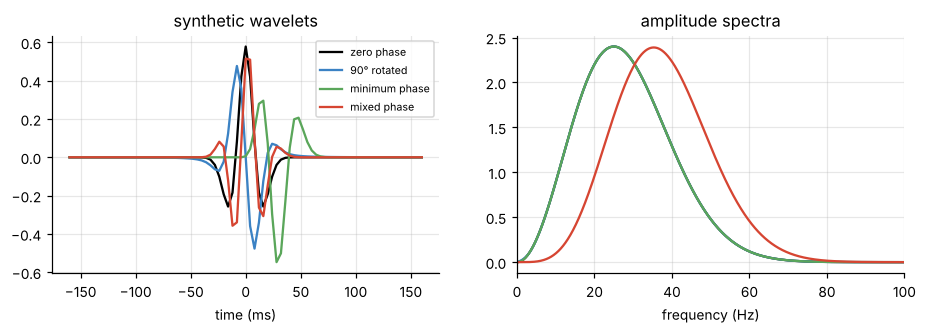

In [4]:
def ricker(f, n=L, dt=DT):
    t = (np.arange(n) - n // 2) * dt
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def rotate_phase(x, theta_deg, axis=-1):
    h = np.imag(signal.hilbert(x, axis=axis))
    th = np.deg2rad(theta_deg)
    return np.cos(th) * x - np.sin(th) * h

def min_phase(w, nf=4096):
    """Minimum-phase signal with the amplitude spectrum of w (folded real cepstrum)."""
    A = np.abs(np.fft.fft(w, nf))
    c = np.fft.ifft(np.log(np.maximum(A, 1e-8 * A.max()))).real
    fold = np.zeros(nf)
    fold[0], fold[nf // 2] = c[0], c[nf // 2]
    fold[1:nf // 2] = 2 * c[1:nf // 2]
    return np.fft.ifft(np.exp(np.fft.fft(fold))).real

def place_causal(wc, n=L):
    out = np.zeros(n)
    k = min(n - n // 2, len(wc))
    out[n // 2:n // 2 + k] = wc[:k]
    return out

def centre_shift(w):
    """Integer shift that would move the envelope centroid of w to the centre sample."""
    env = np.abs(signal.hilbert(w)) ** 2
    return int(np.round((np.arange(len(w)) * env).sum() / env.sum() - len(w) // 2))

def recentre(w):
    return shift(w, -centre_shift(w))

_a = min_phase(ricker(30, 41))[:40]
_b = min_phase(ricker(45, 41))[:40][::-1]
WAVELETS = {
    "zero phase": unit(ricker(25)),
    "90° rotated": unit(rotate_phase(ricker(25), 90)),
    "minimum phase": unit(place_causal(min_phase(ricker(25)))),
    "mixed phase": unit(recentre(np.pad(np.convolve(_a, _b), (1, 1))[:L])),
}

tt = (np.arange(L) - L // 2) * DT * 1000
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for (nm, w), c in zip(WAVELETS.items(), ["k", "#3b82c4", "#5aa65a", "#d64532"]):
    axes[0].plot(tt, w, color=c, label=nm)
    f = np.fft.rfftfreq(4096, DT)
    axes[1].plot(f, np.abs(np.fft.rfft(w, 4096)), color=c)
axes[0].set_xlabel("time (ms)"); axes[0].set_title("synthetic wavelets"); axes[0].legend(fontsize=7)
axes[1].set_xlim(0, 100); axes[1].set_xlabel("frequency (Hz)"); axes[1].set_title("amplitude spectra")
savefig(fig, "01_wavelets"); plt.show()

The zero-phase, 90° and minimum-phase wavelets share one amplitude spectrum: they differ
**only in phase**. Any method that looks only at the amplitude spectrum (or, equivalently,
the autocorrelation) cannot tell them apart. That is the heart of the next section.

## 3. Why this is hard

### 3a. Gauges: scale, sign and shift

For any $c \neq 0$ and any integer $\tau$,

$$
w * r = (c\, S_\tau w) * (c^{-1} S_{-\tau} r),
$$

where $S_\tau$ delays by $\tau$ samples. So the scale, the sign (polarity) and the time shift
of the wavelet can never be recovered from the traces alone. We fix them by convention
($\lVert w \rVert_2 = 1$, wavelet centred) and score every estimate up to sign and shift.

max difference between the two traces: 1.6948638100963698e-07


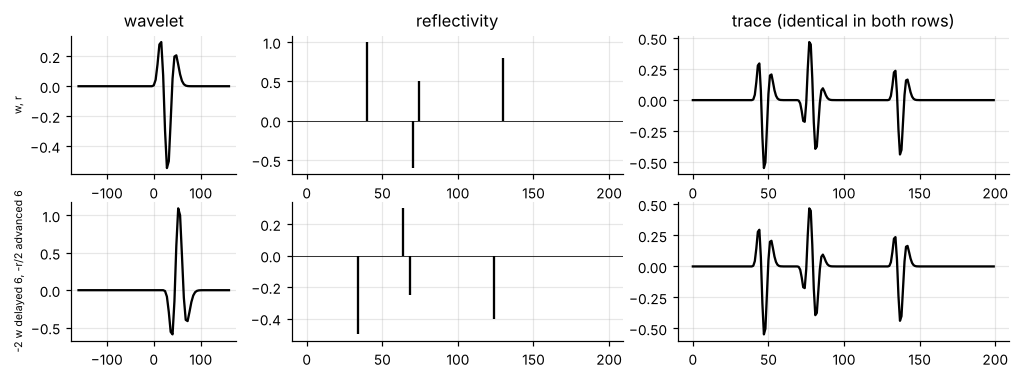

In [5]:
r_demo = np.zeros(200); r_demo[[40, 70, 74, 130]] = [1.0, -0.6, 0.5, 0.8]
w_demo = WAVELETS["minimum phase"]
pairs = [("w, r", w_demo, r_demo), ("-2 w delayed 6, -r/2 advanced 6", -2 * shift(w_demo, 6), -0.5 * shift(r_demo, -6))]
fig, axes = plt.subplots(2, 3, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1, 2, 2]))
for i, (lab, w_, r_) in enumerate(pairs):
    axes[i, 0].plot(tt, w_, "k"); axes[i, 0].set_ylabel(lab, fontsize=7)
    axes[i, 1].vlines(np.arange(200), 0, r_, color="k"); axes[i, 1].axhline(0, color="k", lw=0.5)
    axes[i, 2].plot(conv(r_[None], w_)[0], "k")
axes[0, 0].set_title("wavelet"); axes[0, 1].set_title("reflectivity"); axes[0, 2].set_title("trace (identical in both rows)")
print("max difference between the two traces:", np.abs(conv(r_demo[None], w_demo) - conv(pairs[1][2][None], pairs[1][1])).max())
savefig(fig, "02_gauges"); plt.show()

### 3b. Second-order statistics are blind to phase

If the reflectivity were **white and Gaussian**, the trace would be Gaussian too, and a Gaussian
process is fully described by its autocorrelation, i.e. by $|W(f)|^2$. Every wavelet with the
same amplitude spectrum would then give statistically identical data: phase would be
**unidentifiable**.

What saves us is that real reflectivity is **not Gaussian**: it is spiky (heavy-tailed).
Convolution with a band-limited wavelet mixes many spikes and pushes the trace toward Gaussian
(central limit theorem). Undoing the right wavelet gives back the spikiest output. Kurtosis

$$
\kappa(x) = \frac{\mathbb{E}[x^4]}{(\mathbb{E}[x^2])^2}\qquad (\kappa = 3 \text{ for a Gaussian})
$$

measures this. Below, traces are made with a 60° wavelet, deconvolved with a zero-phase wavelet
of the right amplitude spectrum, and then rotated by a trial angle. For sparse reflectivity the
kurtosis peaks near the true angle; for Gaussian reflectivity it is flat at 3.

Eight random draws of the sparse reflectivity are shown; all peak within a few degrees of 60°
(printed below). Kurtosis is still a fourth-moment statistic dominated by the few largest
spikes, so with few or short traces a phase estimate built on it gets noisy (Section 7.4).

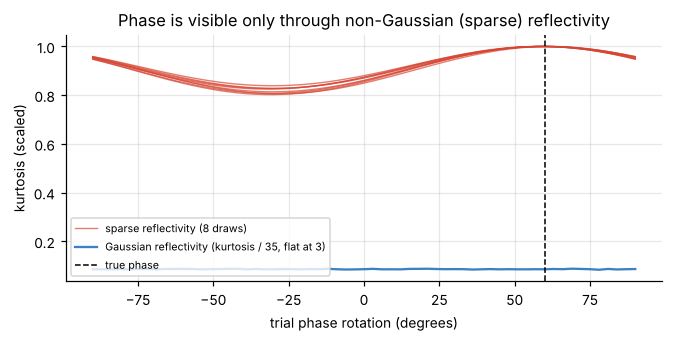

peak angle per sparse draw: [np.int64(60), np.int64(60), np.int64(60), np.int64(60), np.int64(60), np.int64(57), np.int64(60), np.int64(63)] | Gaussian kurtosis range: 2.92 to 3.07


In [6]:
def kurt(x):
    return float(stats.kurtosis(np.ravel(x), fisher=False))

J0, T0, theta_true, nf = 100, 500, 60, 1024
w60 = unit(rotate_phase(ricker(25), theta_true))
thetas = np.arange(-90, 91, 3)
W0 = np.fft.rfft(np.roll(np.pad(unit(ricker(25)), (0, nf - L)), -(L // 2)), nf)

def kurtosis_curve(r_):
    y_ = conv(r_, w60)
    x0 = np.fft.irfft(np.conj(W0) * np.fft.rfft(y_, nf) / (np.abs(W0) ** 2 + 0.05 * np.abs(W0).max() ** 2), nf)[:, :T0]
    k_ = np.array([kurt(rotate_phase(x0, -t)) for t in thetas])
    return k_ / k_.max()

fig, ax = plt.subplots(figsize=(7, 2.9))
peaks = []
for seed in range(8):
    g_ = np.random.default_rng(seed)
    k_ = kurtosis_curve(g_.laplace(size=(J0, T0)) * (g_.random((J0, T0)) < 0.05))
    peaks.append(thetas[np.argmax(k_)])
    ax.plot(thetas, k_, color="#d64532", lw=0.9, alpha=0.7, label="sparse reflectivity (8 draws)" if seed == 0 else None)
g_ = np.random.default_rng(99)
k_g = np.array([kurt(rotate_phase(conv(g_.standard_normal((J0, T0)), w60), -t)) for t in thetas])
ax.plot(thetas, k_g / 35, color="#3b82c4", label="Gaussian reflectivity (kurtosis / 35, flat at 3)")
ax.axvline(theta_true, color="k", ls="--", lw=1, label="true phase")
ax.set_xlabel("trial phase rotation (degrees)"); ax.set_ylabel("kurtosis (scaled)"); ax.legend(fontsize=7, loc="lower left")
ax.set_title("Phase is visible only through non-Gaussian (sparse) reflectivity")
savefig(fig, "03_phase_blindness"); plt.show()
print("peak angle per sparse draw:", peaks, "| Gaussian kurtosis range:", k_g.min().round(2), "to", k_g.max().round(2))

### 3c. Deconvolution is ill-conditioned

The wavelet is a band-pass filter: outside roughly 8 to 60 Hz $|W(f)|$ is near zero. Inverting it
divides noise by those near-zero values. Plain least squares therefore returns a wild,
useless reflectivity. Adding the sparsity prior (an $\ell_1$ penalty, Section 5) gives back
the spikes.

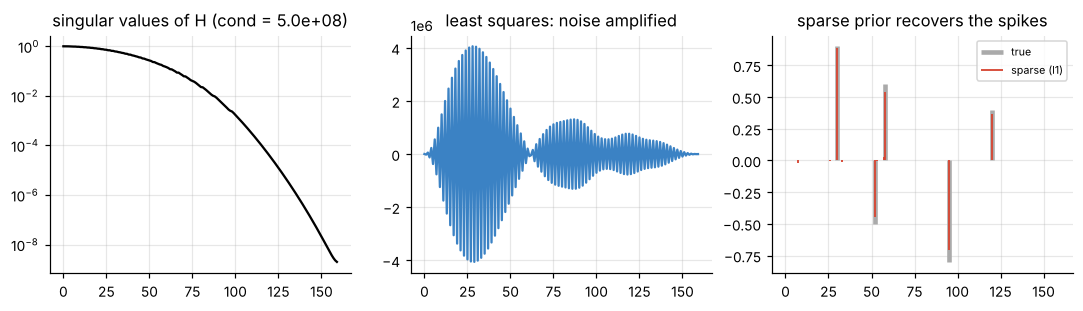

relative error: least squares 14979160.39, sparse 0.09


In [7]:
def soft(z, b):
    return np.sign(z) * np.maximum(np.abs(z) - b, 0)

def sigma2(w, nf=8192):
    """Squared spectral norm of the convolution operator: max_f |W(f)|^2 (Fourier bound)."""
    return float(np.max(np.abs(np.fft.rfft(w, nf)) ** 2))

def lam_max(y, w):
    """Smallest lambda for which r = 0 is optimal, per trace."""
    return np.abs(corr(y, w)).max(axis=-1, keepdims=True)

def fista(y, w, lam, n_iter=200, x0=None, accel=True):
    """min_r 1/2 ||y - w*r||^2 + lam ||r||_1 for every row of y (FISTA, step 1/sigma^2)."""
    a = 1.0 / sigma2(w)
    x = np.zeros_like(y) if x0 is None else x0.copy()
    z, t = x.copy(), 1.0
    for _ in range(n_iter):
        xn = soft(z - a * corr(conv(z, w) - y, w), a * lam)
        if accel:
            tn = 0.5 * (1 + np.sqrt(1 + 4 * t * t))
            z = xn + ((t - 1) / tn) * (xn - x)
            t = tn
        else:
            z = xn
        x = xn
    return x

T1 = 160
r1 = np.zeros(T1); r1[[30, 52, 58, 95, 120]] = [0.9, -0.5, 0.6, -0.8, 0.4]
w1 = unit(ricker(25))
y1 = conv(r1[None], w1)[0] + 0.03 * rng.standard_normal(T1)
Hm = np.array([conv(e[None], w1)[0] for e in np.eye(T1)]).T          # explicit matrix, small case
sv = np.linalg.svd(Hm, compute_uv=False)
r_ls = np.linalg.lstsq(Hm, y1, rcond=None)[0]
r_l1 = fista(y1[None], w1, 0.05 * lam_max(y1[None], w1), 500)[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
axes[0].semilogy(sv / sv[0], "k"); axes[0].set_title(f"singular values of H (cond = {sv[0] / sv[-1]:.1e})")
axes[1].plot(r_ls, color="#3b82c4"); axes[1].set_title("least squares: noise amplified")
axes[2].vlines(np.arange(T1), 0, r1, color="#aaaaaa", lw=3, label="true")
axes[2].vlines(np.arange(T1), 0, r_l1, color="#d64532", lw=1.2, label="sparse (l1)")
axes[2].legend(fontsize=7); axes[2].set_title("sparse prior recovers the spikes")
savefig(fig, "04_ill_conditioned"); plt.show()
print(f"relative error: least squares {np.linalg.norm(r_ls - r1) / np.linalg.norm(r1):.2f}, "
      f"sparse {np.linalg.norm(r_l1 - r1) / np.linalg.norm(r1):.2f}")

### 3d. Thin beds

Two interfaces closer than about a quarter of the dominant period (the *tuning thickness*,
roughly $1/(2.6 f)$, about 15 ms or 4 samples at 25 Hz) merge into one event. Least squares
cannot separate them; a sparse prior can, **if the wavelet is right**. A wavelet with a phase
error turns a clean doublet into extra, false spikes. Section 7.6 measures this.

### 3e. A filter shared by all traces moves into the wavelet

This is the multichannel version of the gauge problem, and the same issue as identifiability of
shared-support kernels in the rainfall notebook. If every trace's reflectivity carries a common
short filter $g$, i.e. $r_j = g * \tilde r_j$, then

$$
y_j = w * g * \tilde r_j = (w * g) * \tilde r_j ,
$$

and $(w * g, \tilde r_j)$ is an equally good, and often **sparser**, explanation. A blind method
then recovers the *effective* wavelet $w * g$, not $w$. Two real sources of such a $g$:
interfaces that are smooth ramps rather than steps (Section 4.2), and the "blue" colour of real
reflectivity (Section 4.1). No method that sees only the traces can separate them.

## 4. Exploratory data analysis

### 4.1 Real reflectivity from six wells

For each well: despike the sonic and density logs with a 13-sample median filter, integrate the
sonic to two-way time, compute impedance and reflectivity at log resolution, and sum the
reflectivity into 4 ms bins. Only the longest gap-free stretch of each log is kept.

In [8]:
WELLS = {"L-30": "L-30.las", "P-129": "P-129_out.LAS", "F02-1": "F02-1_logs.las",
         "F03-2": "F03-2_logs.las", "F03-4": "F03-4_logs.las", "F06-1": "F06-1_logs.las"}

def load_well(name, dt=DT):
    las = lasio.read(os.path.join(DATA, WELLS[name]), engine="normal")
    z = las.index * (0.3048 if las.curves[0].unit.upper().startswith("F") else 1.0)
    dtl, rho = las["DT"].astype(float), las["RHOB"].astype(float)
    ok = np.isfinite(dtl) & np.isfinite(rho) & (dtl > 0) & (rho > 0)
    runs = np.split(np.arange(len(ok)), np.flatnonzero(np.diff(ok.astype(int))) + 1)
    run = max([r_ for r_ in runs if ok[r_[0]]], key=len)
    z, dtl, rho = z[run], dtl[run], rho[run]
    slow = dtl * 1e-6 / 0.3048 if np.median(dtl) < 150 else dtl * 1e-6   # us/ft or us/m -> s/m
    rho = rho / 1000 if np.median(rho) > 100 else rho                    # g/cc
    slow, rho = ndimage.median_filter(slow, 13), ndimage.median_filter(rho, 13)
    twt = 2 * np.cumsum(slow * np.diff(z, prepend=z[0]))
    Z = rho / slow
    r_fine = np.diff(Z) / (Z[1:] + Z[:-1])
    nb = int(twt[-1] / dt)
    bins = np.minimum((twt[1:] / dt).astype(int), nb - 1)
    return dict(name=name, z=z, twt=twt, vp=1 / slow, rho=rho, Z=Z,
                r=np.bincount(bins, weights=r_fine, minlength=nb))

wells = {n: load_well(n) for n in WELLS}
rows = []
for n, d in wells.items():
    r_ = d["r"]
    rows.append(dict(well=n, duration_s=len(r_) * DT, depth_m=f"{d['z'][0]:.0f}-{d['z'][-1]:.0f}",
                     kurtosis=kurt(r_), lag1_autocorr=np.corrcoef(r_[:-1], r_[1:])[0, 1],
                     frac_above_10pct=np.mean(np.abs(r_) > 0.1 * np.abs(r_).max())))
well_table = pd.DataFrame(rows).set_index("well").round(3)
well_table

,duration_s,depth_m,kurtosis,lag1_autocorr,frac_above_10pct
well,,,,,
L-30,1.860,932-4238,6.942,-0.398,0.447
P-129,0.680,285-1937,9.037,-0.252,0.412
F02-1,1.212,262-1500,6.499,-0.159,0.422
F03-2,1.824,30-2140,14.745,-0.116,0.239
F03-4,1.768,30-1860,9.783,-0.373,0.342
F06-1,1.592,29-1700,33.313,0.027,0.151


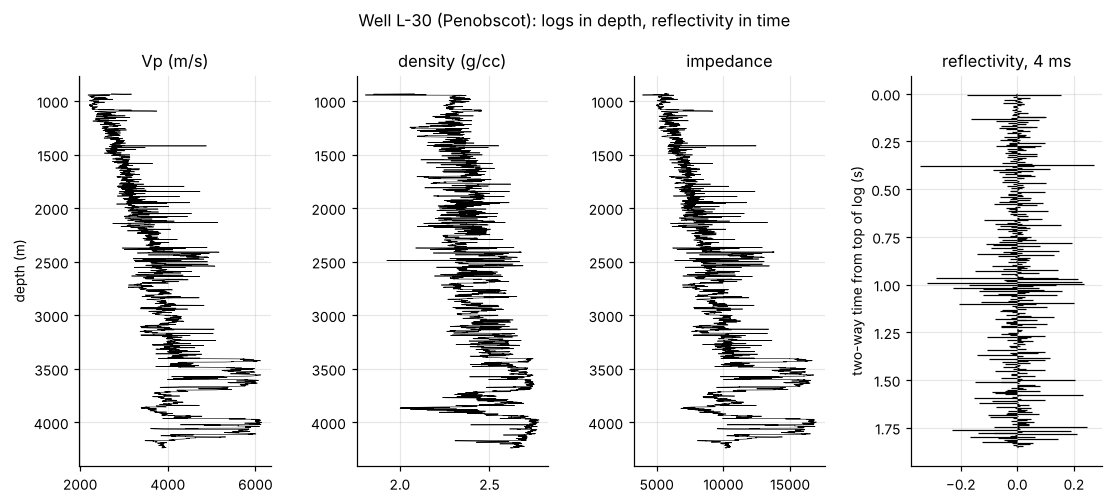

In [9]:
d = wells["L-30"]
fig, axes = plt.subplots(1, 4, figsize=(12, 4.6), sharey=False)
fig.subplots_adjust(wspace=0.45)
axes[0].plot(d["vp"], d["z"], lw=0.4, color="k"); axes[0].set_title("Vp (m/s)"); axes[0].invert_yaxis(); axes[0].set_ylabel("depth (m)")
axes[1].plot(d["rho"], d["z"], lw=0.4, color="k"); axes[1].set_title("density (g/cc)"); axes[1].invert_yaxis()
axes[2].plot(d["Z"], d["z"], lw=0.4, color="k"); axes[2].set_title("impedance"); axes[2].invert_yaxis()
tr_ = np.arange(len(d["r"])) * DT
axes[3].hlines(tr_, 0, d["r"], color="k", lw=0.8); axes[3].set_title("reflectivity, 4 ms"); axes[3].invert_yaxis()
axes[3].set_ylabel("two-way time from top of log (s)")
fig.suptitle("Well L-30 (Penobscot): logs in depth, reflectivity in time", y=1.01)
savefig(fig, "05_well_L30"); plt.show()

Now the statistics that matter for blind deconvolution: is real reflectivity **sparse**, and is
it **white**?

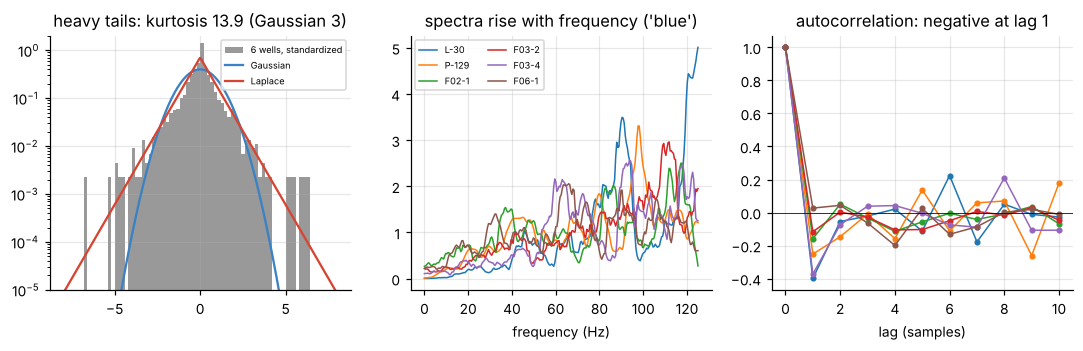

In [10]:
all_r = np.concatenate([d["r"] / np.std(d["r"]) for d in wells.values()])
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
bins_ = np.linspace(-8, 8, 81)
axes[0].hist(all_r, bins=bins_, density=True, color="#999999", label="6 wells, standardized")
xg = np.linspace(-8, 8, 400)
axes[0].plot(xg, stats.norm.pdf(xg), "#3b82c4", label="Gaussian")
axes[0].plot(xg, stats.laplace.pdf(xg, scale=1 / np.sqrt(2)), "#d64532", label="Laplace")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-5, 2); axes[0].legend(fontsize=6, loc="upper right")
axes[0].set_title(f"heavy tails: kurtosis {kurt(all_r):.1f} (Gaussian 3)")
f = np.fft.rfftfreq(512, DT)
for n, d in wells.items():
    r_ = d["r"] - d["r"].mean()
    P = np.abs(np.fft.rfft(r_ * signal.windows.hann(len(r_)), 512)) ** 2
    axes[1].plot(f, ndimage.uniform_filter1d(P / P.mean(), 15), lw=1, label=n)
axes[1].set_xlabel("frequency (Hz)"); axes[1].set_title("spectra rise with frequency ('blue')"); axes[1].legend(fontsize=6, ncol=2)
for n, d in wells.items():
    r_ = d["r"] - d["r"].mean()
    ac = np.correlate(r_, r_, "full")[len(r_) - 1:len(r_) + 10]
    axes[2].plot(ac / ac[0], marker=".", lw=1)
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_xlabel("lag (samples)"); axes[2].set_title("autocorrelation: negative at lag 1")
savefig(fig, "06_reflectivity_statistics"); plt.show()

**What the wells say.**

* Reflectivity is clearly **non-Gaussian** (kurtosis well above 3; see the table), so phase is
  identifiable in principle (3b).
* It is **not sparse** in the strict sense: most samples are small but not zero, closer to a
  Laplace distribution than to a few isolated spikes. An $\ell_1$ penalty is the matching prior
  for a Laplace distribution, which supports the choice made in Section 5.
* It is **not white**: spectra rise with frequency and lag-1 autocorrelation is negative. This is
  a known property of well-log reflectivity. By 3e it is a common filter that the blind
  wavelet will partly absorb, and it also biases any wavelet amplitude spectrum estimated
  from the traces under a white-reflectivity assumption.

### 4.2 A 2D impedance model (PyLops)

A laterally continuous, blocky model, used as a second synthetic test bed. Depth samples (4 m)
are used directly as 4 ms time samples.

first strong reflectors at position 400: [26 48 49 58 59 74]
values around one interface: [0.   0.   0.01 0.01 0.   0.  ]
mean lag-1 autocorrelation 0.49, kurtosis 54.6


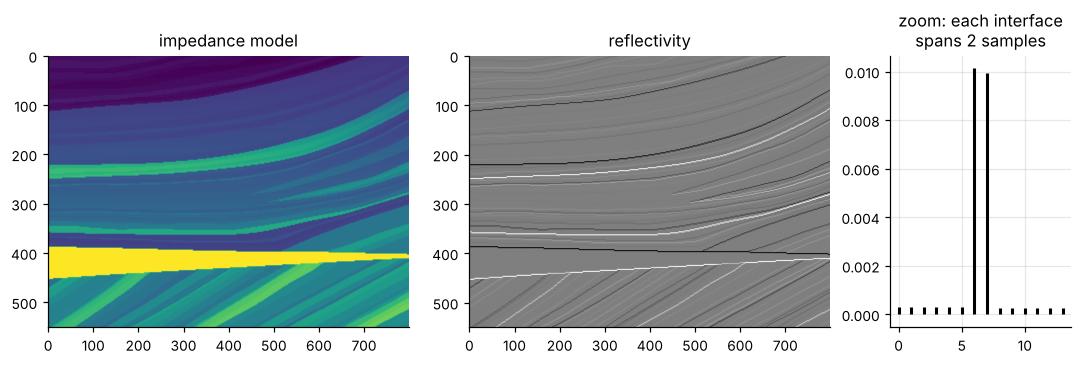

In [11]:
pm = np.load(os.path.join(DATA, "poststack_model.npz"))
Zm = pm["model"]                                  # (550 depth samples, 800 positions)
R_pylops = 0.5 * np.diff(np.log(Zm), axis=0).T    # (800, 549) reflectivity, one row per position
lag1 = np.mean([np.corrcoef(r_[:-1], r_[1:])[0, 1] for r_ in R_pylops])
k = 400; idx = np.flatnonzero(np.abs(R_pylops[k]) > 0.01)[:6]
print("first strong reflectors at position 400:", idx)
print("values around one interface:", R_pylops[k, idx[0] - 2:idx[0] + 4].round(4))
print(f"mean lag-1 autocorrelation {lag1:.2f}, kurtosis {kurt(R_pylops):.1f}")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[2, 2, 1]))
axes[0].imshow(Zm, aspect="auto", cmap="viridis"); axes[0].set_title("impedance model"); axes[0].grid(False)
vm = np.percentile(np.abs(R_pylops), 99)
axes[1].imshow(R_pylops.T, aspect="auto", cmap="gray_r", vmin=-vm, vmax=vm); axes[1].set_title("reflectivity"); axes[1].grid(False)
seg = R_pylops[k, idx[0] - 6:idx[0] + 8]
axes[2].vlines(np.arange(len(seg)), 0, seg, color="k", lw=2); axes[2].set_title("zoom: each interface\nspans 2 samples")
savefig(fig, "07_pylops_model"); plt.show()

Every interface is spread over **two equal samples** (lag-1 autocorrelation near 0.5). In the
language of 3e this reflectivity is $g * \tilde r$ with $g \approx [\tfrac12, \tfrac12]$, a
half-sample delay and a slight low-pass. Section 7.5 shows what that does to a blind estimate.

### 4.3 Field data: Penobscot crossline 1155 and well L-30

401 traces (inlines 1100 to 1500), 4 s at 4 ms. To place L-30, its reflectivity is convolved
with a 25 Hz Ricker wavelet and correlated with every trace over all bulk time shifts.

best tie: trace 82 (inline 1182), log top at 0.980 s, correlation 0.48


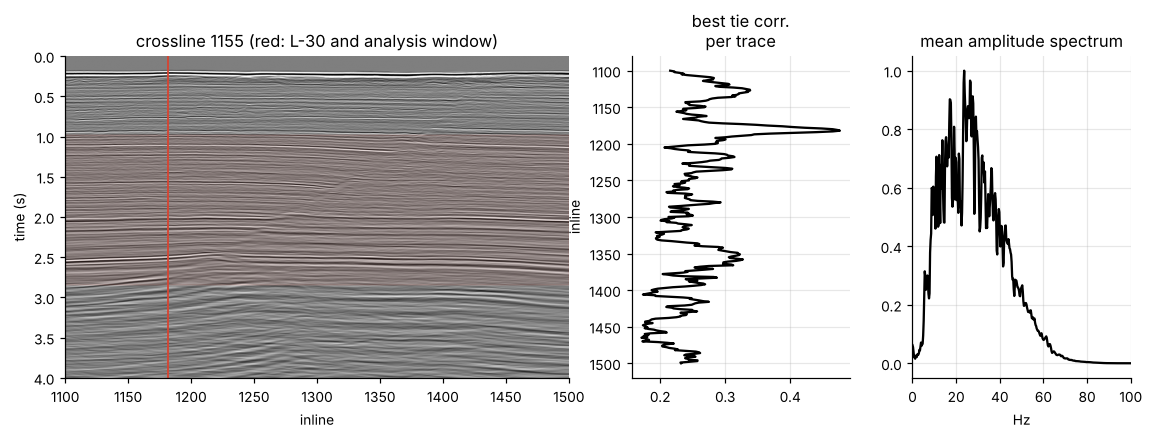

field window: 401 traces x 465 samples, kurtosis of traces 4.69


In [12]:
raw = np.loadtxt(os.path.join(DATA, "PenobXL_1155.txt"))
inlines, S = raw[:, 0].astype(int), raw[:, 2:]
r_well = wells["L-30"]["r"]
syn0 = np.convolve(r_well, ricker(25, 41), "same")
tie_scan = np.zeros((S.shape[0], S.shape[1] - len(r_well)))
for j in range(S.shape[0]):
    seg_ = np.lib.stride_tricks.sliding_window_view(S[j], len(r_well))[:tie_scan.shape[1]]
    tie_scan[j] = seg_ @ syn0 / (np.linalg.norm(seg_, axis=1) * np.linalg.norm(syn0) + 1e-9)
j_well, s_well = np.unravel_index(np.argmax(np.abs(tie_scan)), tie_scan.shape)
print(f"best tie: trace {j_well} (inline {inlines[j_well]}), log top at {s_well * DT:.3f} s, "
      f"correlation {tie_scan[j_well, s_well]:.2f}")

win = slice(s_well, s_well + len(r_well))         # analysis window = span of the well log
Y_field = S[:, win] / np.std(S[:, win])
t_ax = np.arange(S.shape[1]) * DT
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), gridspec_kw=dict(width_ratios=[3, 1.3, 1.3]))
vm = np.percentile(np.abs(S), 99)
axes[0].imshow(S.T, aspect="auto", cmap="gray_r", vmin=-vm, vmax=vm,
               extent=[inlines[0], inlines[-1], t_ax[-1], 0])
axes[0].axvline(inlines[j_well], color="#d64532", lw=1.2)
axes[0].axhspan(win.start * DT, win.stop * DT, color="#d64532", alpha=0.08)
axes[0].set_title("crossline 1155 (red: L-30 and analysis window)"); axes[0].set_xlabel("inline"); axes[0].set_ylabel("time (s)"); axes[0].grid(False)
axes[1].plot(np.abs(tie_scan).max(1), inlines, "k"); axes[1].invert_yaxis(); axes[1].set_title("best tie corr.\nper trace"); axes[1].set_ylabel("inline")
f = np.fft.rfftfreq(1024, DT)
P = (np.abs(np.fft.rfft(Y_field * signal.windows.tukey(Y_field.shape[1], 0.1), 1024)) ** 2).mean(0)
axes[2].plot(f, np.sqrt(P / P.max()), "k"); axes[2].set_xlim(0, 100); axes[2].set_title("mean amplitude spectrum"); axes[2].set_xlabel("Hz")
savefig(fig, "08_field_overview"); plt.show()
print(f"field window: {Y_field.shape[0]} traces x {Y_field.shape[1]} samples, kurtosis of traces {kurt(Y_field):.2f}")

The best tie is at inline 1182. The original SEG tutorial puts L-30 at the 77th trace from
the start of this line (inline 1177), five traces away, so the location is consistent. The tie uses
only a bulk shift (no stretch), so 0.48 is a modest but usable correlation. The analysis
window covers the logged interval, about 1.0 to 2.8 s. The traces have kurtosis close to 3:
convolution has made them nearly Gaussian, as 3b predicts.

## 5. First-principles design

### 5.1 Objective

With a Laplace prior on reflectivity and Gaussian noise, the MAP estimate solves

$$
\min_{w,\; r_1,\dots,r_J}\;\; \sum_{j=1}^{J} \Big[\tfrac12 \lVert y_j - w * r_j \rVert_2^2 + \lambda_j \lVert r_j \rVert_1\Big]
\quad \text{s.t.}\quad \lVert w\rVert_2 = 1,\;\; \operatorname{supp}(w) \subseteq \{-\lfloor L/2\rfloor,\dots,\lfloor L/2\rfloor\}.
$$

The norm constraint fixes the scale gauge (without it, $w \to \infty$, $r \to 0$ drives the
penalty to zero). The finite support is the only constraint on the wavelet's shape.

### 5.2 Alternating minimisation (AM)

The problem is bi-convex: convex in $r$ for fixed $w$, and convex in $w$ for fixed $r$.
We alternate:

**Reflectivity step** (all traces in parallel): FISTA on
$\tfrac12\lVert y_j - w*r_j\rVert^2 + \lambda_j\lVert r_j\rVert_1$,

$$
r^{k+1} = \operatorname{soft}\!\big(z^k - \alpha\, w \star (w * z^k - y),\; \alpha\lambda\big),\qquad
\alpha = \frac{1}{\max_f |W(f)|^2},
$$

with the Nesterov extrapolation $z^{k+1} = r^{k+1} + \tfrac{t_k - 1}{t_{k+1}}(r^{k+1} - r^k)$.
The step uses the exact Lipschitz constant $\lVert H \rVert^2 = \max_f |W(f)|^2$ (one FFT).

**Wavelet step**: with $r$ fixed, the wavelet solves a small least-squares problem whose
normal equations are Toeplitz:

$$
\Big(\sum_j A_{r_j} + \mu I\Big)\, w = \sum_j c_{y_j r_j}, \qquad
(A_r)_{k\ell} = \sum_t r(t-k)\,r(t-\ell) = a_r(k-\ell),\quad (c_{yr})_k = \sum_t y(t)\, r(t-k),
$$

solved by Levinson recursion in $O(L^2)$. Trace-edge terms are ignored (a relative error below
1% here, checked below). Then $w \leftarrow w/\lVert w\rVert$ and $r \leftarrow r\,\lVert w\rVert$.

**Gauge fixing**: after each wavelet step, shift $w$ so its envelope centroid sits at the
centre sample, and shift $r$ the opposite way. Sign is left free and handled in scoring.

**$\lambda$ per trace and continuation.** $\lambda_j = \rho\,\lambda_{\max,j}$ with
$\lambda_{\max,j} = \lVert w \star y_j \rVert_\infty$ (the smallest value that makes
$r_j = 0$ optimal), so traces of different strength are treated alike. $\rho$ starts at 0.5
and decreases geometrically to 0.05: strong reflectors fix the wavelet first, weaker ones
are added later. This avoids early overfitting of noise into the codes.

**Initialisation**: the zero-phase statistical wavelet (baseline B1 below).

**Relation to DUNL.** DUNL trains the kernel by back-propagating through an unrolled encoder.
In the rainfall notebook, treating the codes as constants when updating the kernel
(`grad_through_encoder=False`, which is exactly this alternating scheme) gave the same test
fit (NSE 0.963 against 0.964) at lower cost. Here the wavelet step even has a closed form, so
AM is the natural choice.

### 5.3 A variant: keep the amplitude spectrum, learn only the phase (AM-amp)

Section 3b says second-order statistics identify $|W(f)|$ (if reflectivity is white) and
only higher-order structure (sparsity) identifies phase. So a cautious variant projects every
wavelet update onto the statistical amplitude spectrum $A(f)$ and lets sparsity choose only
the phase:

$$
W(f) \leftarrow A(f)\, e^{\,i \angle W(f)} .
$$

In [13]:
def wavelet_ls(y, r, Lw=L, ridge=1e-2):
    """argmin_w sum_j ||y_j - r_j * w||^2 + ridge * a_r(0) * ||w||^2, w centred of length Lw."""
    T, h = y.shape[-1], Lw // 2
    nf = nfft_for(2 * T + Lw)
    R = np.fft.rfft(r, nf)
    ac = np.fft.irfft((np.abs(R) ** 2).sum(0), nf)[:Lw]
    cc = np.fft.irfft((np.fft.rfft(y, nf) * np.conj(R)).sum(0), nf)
    b = cc[(np.arange(Lw) - h) % nf]
    col = ac.copy(); col[0] += ridge * ac[0] + 1e-12
    return linalg.solve_toeplitz(col, b)

_rt = rng.standard_normal((20, 300)) * (rng.random((20, 300)) < 0.05)
_wt = WAVELETS["minimum phase"]
print("wavelet step, noise-free with true r: max error",
      np.abs(wavelet_ls(conv(_rt, _wt), _rt, ridge=0) - _wt).max().round(4), "(edge terms ignored)")

wavelet step, noise-free with true r: max error 0.02 (edge terms ignored)


In [14]:
def taper(T, frac=0.1):
    return signal.windows.tukey(T, frac)

def stat_amplitude(y, nf=4096, smooth=9):
    """sqrt of the trace-averaged power spectrum (white-reflectivity assumption)."""
    P = (np.abs(np.fft.rfft(y * taper(y.shape[-1]), nf)) ** 2).mean(0)
    return np.sqrt(np.convolve(P, np.ones(smooth) / smooth, mode="same"))

def from_spectrum(Wf, Lw=L, nf=4096):
    """Centred, tapered, unit-norm wavelet from a one-sided spectrum on an nf grid."""
    w = np.roll(np.fft.irfft(Wf, nf), Lw // 2)[:Lw] * signal.windows.tukey(Lw, 0.3)
    return unit(w)

def spectrum_of(w, nf=4096):
    Lw = len(w)
    return np.fft.rfft(np.roll(np.pad(w, (0, nf - Lw)), -(Lw // 2)), nf)

def project_amplitude(w, A, nf=4096):
    return from_spectrum(A * np.exp(1j * np.angle(spectrum_of(w, nf))), len(w), nf)

def blind_am(y, Lw=L, w0=None, outer=40, inner=60, rho_start=0.5, rho_end=0.05, ridge=1e-2,
             amp=None, track=None):
    """Alternating minimisation for multichannel sparse blind deconvolution.
    amp: optional amplitude spectrum to project the wavelet on (AM-amp).
    track: optional true wavelet, to record the wavelet error per outer iteration."""
    w = est_zero_phase(y, Lw) if w0 is None else unit(w0.copy())
    x, hist = None, []
    rhos = np.geomspace(rho_start, rho_end, max(outer // 2, 1))
    for k in range(outer):
        rho = rhos[min(k, len(rhos) - 1)]
        lam = rho * lam_max(y, w)
        x = fista(y, w, lam, inner, x0=x)
        if not np.any(x):
            continue
        wn = wavelet_ls(y, x, Lw, ridge)
        if amp is not None:
            wn = project_amplitude(wn, amp) * np.linalg.norm(wn)
        nrm = np.linalg.norm(wn)
        w, x = wn / nrm, x * nrm
        s = centre_shift(w)
        if s:
            w, x = shift(w, -s), shift(x, s)
        if track is not None:
            obj = 0.5 * np.sum((conv(x, w) - y) ** 2) + np.sum(lam * np.abs(x))
            hist.append(dict(outer=k, rho=rho, objective=obj, wavelet_corr=best_align(w, track)[0]))
    x = fista(y, w, rho_end * lam_max(y, w), 300, x0=x)
    return (w, x, pd.DataFrame(hist)) if track is not None else (w, x)

## 6. Baselines

Each baseline makes one classical assumption about the wavelet's phase.

| | method | amplitude spectrum | phase | assumption |
|---|---|---|---|---|
| B1 | zero-phase statistical | $\sqrt{\text{mean}_j |Y_j(f)|^2}$ | 0 | white reflectivity, zero-phase wavelet |
| B2 | minimum-phase (as in Wiener spiking deconvolution) | same | minimum phase (Kolmogorov) | white reflectivity, impulsive source |
| B3 | constant phase by kurtosis maximisation | same | one constant $\theta$ that maximises kurtosis of the deconvolved output | non-Gaussian reflectivity, near-constant phase |
| B4 | homomorphic (cepstral), averaged over traces | from the cepstrum | from the cepstrum | wavelet and reflectivity separate in quefrency |
| AM | sparse blind deconvolution (5.2) | learned | learned | sparse (Laplace) reflectivity |
| AM-amp | AM with amplitude projection (5.3) | from B1 | learned | as AM, plus white reflectivity for the amplitude |

B3 follows the kurtosis-maximisation idea used for seismic wavelet phase estimation (associated
with van der Baan's work; reference to be checked). B4 is the homomorphic approach, which
goes back to Ulrych's work on cepstral deconvolution (reference to be checked). For B4 the complex
cepstrum of each tapered trace is computed with an exponential weight
$\alpha^t$, $\alpha = 0.995$ (which pushes zeros away from the unit circle and makes phase
unwrapping stable), the linear-phase term is removed, the cepstra are averaged over traces, and
a low-pass lifter $|q| \le L/2$ keeps the wavelet part.

For a fair comparison every wavelet estimate is followed by the **same** reflectivity step:
FISTA with $\lambda_j = 0.05\,\lambda_{\max,j}$, 300 iterations. An **oracle** that uses the
true wavelet gives the upper bound.

In [15]:
def est_zero_phase(y, Lw=L):
    return from_spectrum(stat_amplitude(y), Lw)

def est_min_phase(y, Lw=L, nf=4096):
    w0 = np.fft.irfft(stat_amplitude(y, nf), nf)
    wm = min_phase(np.roll(w0, nf // 2)[nf // 2 - 2 * Lw:nf // 2 + 2 * Lw], nf)
    return unit(place_causal(wm, Lw) * signal.windows.tukey(Lw, 0.3))

def est_kurtosis(y, Lw=L, eps=0.05, thetas=np.arange(-90, 91, 2)):
    w0 = est_zero_phase(y, Lw)
    nf = nfft_for(y.shape[-1] + Lw)
    W = spectrum_of(w0, nf)
    x0 = np.fft.irfft(np.conj(W) * np.fft.rfft(y, nf) / (np.abs(W) ** 2 + eps * np.max(np.abs(W)) ** 2), nf)[..., :y.shape[-1]]
    ks = np.array([kurt(rotate_phase(x0, -t)) for t in thetas])
    th = thetas[int(np.argmax(ks))]
    return unit(rotate_phase(w0, th)), th, ks

def est_homomorphic(y, Lw=L, nf=4096, alpha=0.995):
    T = y.shape[-1]
    n = np.arange(T)
    cs = []
    for tr in y:
        X = np.fft.fft(tr * taper(T) * alpha ** n, nf)
        ph = np.unwrap(np.angle(X))
        ph -= np.pi * np.round(ph[nf // 2] / np.pi) * np.arange(nf) / (nf // 2)   # remove linear phase
        cs.append(np.fft.ifft(np.log(np.abs(X) + 1e-10 * np.abs(X).max()) + 1j * ph).real)
    c = np.mean(cs, 0)
    q0 = Lw // 2
    lift = np.zeros(nf); lift[:q0 + 1] = 1; lift[-q0:] = 1
    w = np.fft.ifft(np.exp(np.fft.fft(c * lift))).real
    ns = np.where(np.arange(nf) < nf // 2, np.arange(nf), np.arange(nf) - nf)
    w = w / alpha ** ns
    w = np.concatenate([w[-(Lw // 2):], w[:Lw - Lw // 2]]) * signal.windows.tukey(Lw, 0.3)
    return unit(recentre(w))

def estimate_all(y, Lw=L, which=("B1", "B2", "B3", "B4", "AM", "AM-amp")):
    out = {}
    if "B1" in which: out["B1"] = est_zero_phase(y, Lw)
    if "B2" in which: out["B2"] = est_min_phase(y, Lw)
    if "B3" in which: out["B3"] = est_kurtosis(y, Lw)[0]
    if "B4" in which: out["B4"] = est_homomorphic(y, Lw)
    if "AM" in which: out["AM"] = blind_am(y, Lw)[0]
    if "AM-amp" in which: out["AM-amp"] = blind_am(y, Lw, amp=stat_amplitude(y))[0]
    return out

### 6.1 Metrics

All metrics are invariant to the gauges (scale, sign, shift up to $\pm 15$ samples).

* **Wavelet correlation** $\displaystyle \max_{\tau,\,s=\pm1} \frac{\langle w, s\,S_\tau \hat w\rangle}{\lVert w\rVert\,\lVert \hat w\rVert}$ (1 is perfect).
* **Phase error**: after aligning, the constant rotation $\theta$ that best maps $\hat w$ onto $w$, in $[-90°, 90°]$, reported as $|\theta|$. Because a time shift is a gauge, part of a large phase error can be traded for a shift, so this is the phase error **left after the best bulk shift**. Large errors are compressed: a zero-phase estimate of a 60° wavelet scores about 22°, not 60°.
* **Spike F1**: reflectors are samples above 10% of the trace maximum, matched within $\pm 1$ sample (for the sparse and blocky data sets).
* **Reflectivity correlation** between the true and the recovered reflectivity, after the same shift and sign as the wavelet.

In [16]:
def best_align(w_est, w_true, max_shift=15):
    a, best = unit(w_true), (-1.0, 0, 1.0)
    for s in range(-max_shift, max_shift + 1):
        b = shift(w_est, s); nb = np.linalg.norm(b)
        if nb > 0:
            c = float(a @ b) / nb
            if abs(c) > best[0]:
                best = (abs(c), s, float(np.sign(c)))
    return best

def phase_error(w_est, w_true, max_shift=15):
    _, s, sg = best_align(w_est, w_true, max_shift)
    b = sg * shift(w_est, s)
    th = np.arange(-90, 91)
    return float(th[int(np.argmax([unit(w_true) @ unit(rotate_phase(b, t)) for t in th]))])

def spike_f1(r_est, r_true, tol=1, rel=0.1):
    tp = fp = fn = 0
    for re_, rt_ in zip(r_est, r_true):
        if not np.any(rt_):
            continue
        pt = np.flatnonzero(np.abs(rt_) > rel * np.abs(rt_).max())
        pe = np.flatnonzero(np.abs(re_) > rel * max(np.abs(re_).max(), 1e-12))
        used = np.zeros(len(pe), bool)
        for p in pt:
            dd = np.abs(pe - p).astype(float); dd[used] = np.inf
            if len(dd) and dd.min() <= tol:
                used[np.argmin(dd)] = True; tp += 1
            else:
                fn += 1
        fp += int((~used).sum())
    return 2 * tp / max(2 * tp + fp + fn, 1)

def ncorr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

def evaluate(y, R_true, w_true, est, rho=0.05, f1=True):
    rows = []
    for m, w_hat in {"oracle": w_true, **est}.items():
        c, s, sg = best_align(w_hat, w_true)
        x = fista(y, w_hat, rho * lam_max(y, w_hat), 300)
        x_al = sg * shift(x, -s)
        rows.append(dict(method=m, wavelet_corr=c, phase_err=abs(phase_error(w_hat, w_true)),
                         spike_f1=spike_f1(x_al, R_true) if f1 else np.nan, refl_corr=ncorr(x_al, R_true)))
    return rows

def add_noise(y0, snr_db, rng):
    return y0 + np.std(y0) / 10 ** (snr_db / 20) * rng.standard_normal(y0.shape)

## 7. Experiments with a known answer

Three synthetic test beds, from easy to realistic:

| | reflectivity | traces $\times$ samples | what it tests |
|---|---|---|---|
| **S0 sparse** | i.i.d. Bernoulli(5%) $\times$ Laplace | 100 $\times$ 500 | the model holds exactly |
| **S1 blocky 2D** | PyLops model, every 8th position | 100 $\times$ 549 | lateral continuity, ramped interfaces (3e) |
| **S2 real logs** | six wells, 200-sample windows, hop 50 | 24 $\times$ 200 | real, coloured, non-sparse reflectivity |

Noise: Gaussian, SNR 10 dB (signal std over noise std) unless stated. Two noise seeds per case.

In [17]:
def make_S0(J=100, T=500, density=0.05, seed=0):
    g = np.random.default_rng(seed)
    return g.laplace(size=(J, T)) * (g.random((J, T)) < density)

S1_R = R_pylops[::8]
S2_R = np.array([d["r"][s:s + 200] for d in wells.values() for s in range(0, len(d["r"]) - 199, 50)])
TESTBEDS = {"S0 sparse": make_S0(seed=100), "S1 blocky 2D": S1_R, "S2 real logs": S2_R}
print({k: v.shape for k, v in TESTBEDS.items()})

{'S0 sparse': (100, 500), 'S1 blocky 2D': (100, 549), 'S2 real logs': (24, 200)}


### 7.1 Convergence of AM on one case

S0 with the 90° wavelet, starting from the zero-phase estimate (which is 90° wrong).

AM time 5.7 s, final wavelet correlation 0.999


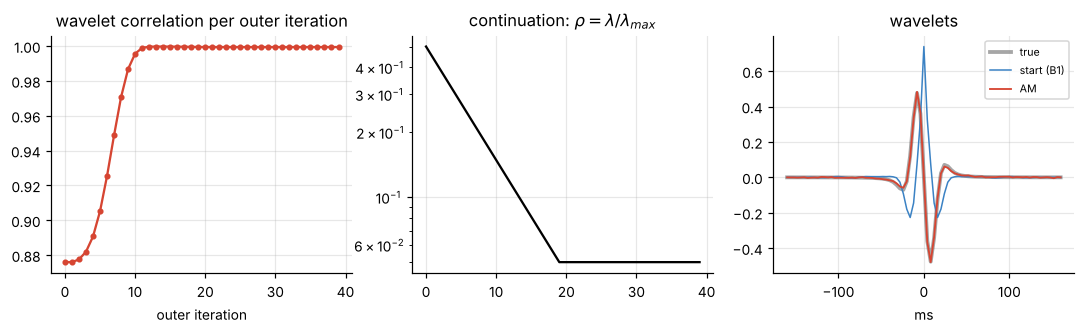

In [18]:
y_c = add_noise(conv(TESTBEDS["S0 sparse"], WAVELETS["90° rotated"]), SNR_DB, np.random.default_rng(1))
t0 = time.time()
w_c, x_c, hist_c = blind_am(y_c, track=WAVELETS["90° rotated"])
print(f"AM time {time.time() - t0:.1f} s, final wavelet correlation {hist_c.wavelet_corr.iloc[-1]:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
axes[0].plot(hist_c.outer, hist_c.wavelet_corr, "o-", color=COL["AM"], ms=3); axes[0].set_title("wavelet correlation per outer iteration"); axes[0].set_xlabel("outer iteration")
axes[1].plot(hist_c.outer, hist_c.rho, "k"); axes[1].set_yscale("log"); axes[1].set_title(r"continuation: $\rho = \lambda/\lambda_{max}$")
_, s_, sg_ = best_align(w_c, WAVELETS["90° rotated"])
axes[2].plot(tt, WAVELETS["90° rotated"], color=COL["truth"], lw=2.5, alpha=0.4, label="true")
axes[2].plot(tt, est_zero_phase(y_c), color=COL["B1"], lw=1, label="start (B1)")
axes[2].plot(tt, sg_ * shift(w_c, s_), color=COL["AM"], lw=1.2, label="AM")
axes[2].legend(fontsize=7); axes[2].set_xlabel("ms"); axes[2].set_title("wavelets")
savefig(fig, "09_am_convergence"); plt.show()

### 7.2 Main comparison

In [19]:
t0 = time.time()
rows = []
for tb, R_ in TESTBEDS.items():
    for wn, w_ in WAVELETS.items():
        for seed in range(2):
            y_ = add_noise(conv(R_, w_), SNR_DB, np.random.default_rng(10 + seed))
            est = estimate_all(y_)
            for row in evaluate(y_, R_, w_, est, f1=(tb != "S2 real logs")):
                rows.append(dict(testbed=tb, wavelet=wn, seed=seed, **row))
main = pd.DataFrame(rows)
main.to_csv(f"{RES}/main_comparison.csv", index=False)
print(f"{time.time() - t0:.0f} s")
order = ["oracle", "B1", "B2", "B3", "B4", "AM", "AM-amp"]
summary_main = (main.groupby(["testbed", "method"])[["wavelet_corr", "phase_err", "spike_f1", "refl_corr"]]
                .mean().round(3).reindex(order, level=1))
summary_main

299 s


wavelet_corr  phase_err  spike_f1  refl_corr
testbed      method                                              
S0 sparse    oracle         1.000      0.000     0.836      0.945
             B1             0.908     14.000     0.558      0.694
             B2             0.913     10.625     0.529      0.687
             B3             0.969      4.250     0.634      0.849
             B4             0.855      9.375     0.426      0.529
             AM             0.999      0.000     0.832      0.944
             AM-amp         0.976      1.625     0.662      0.871
S1 blocky 2D oracle         1.000      0.000     0.789      0.952
             B1             0.909     14.000     0.630      0.788
             B2             0.915      8.250     0.612      0.779
             B3             0.963      5.000     0.747      0.919
             B4             0.178     28.375     0.222      0.207
             AM             0.931     20.500     0.556      0.718
             AM-amp         0.912     19.625     0.654      0.782
S2 real logs oracle         1.000      0.000       NaN      0.317
             B1             0.895     13.625       NaN      0.317
             B2             0.898     11.500       NaN      0.275
             B3             0.939      7.875       NaN      0.341
             B4             0.793     12.750       NaN      0.239
             AM             0.874      9.500       NaN      0.305
             AM-amp         0.898     10.125       NaN      0.309

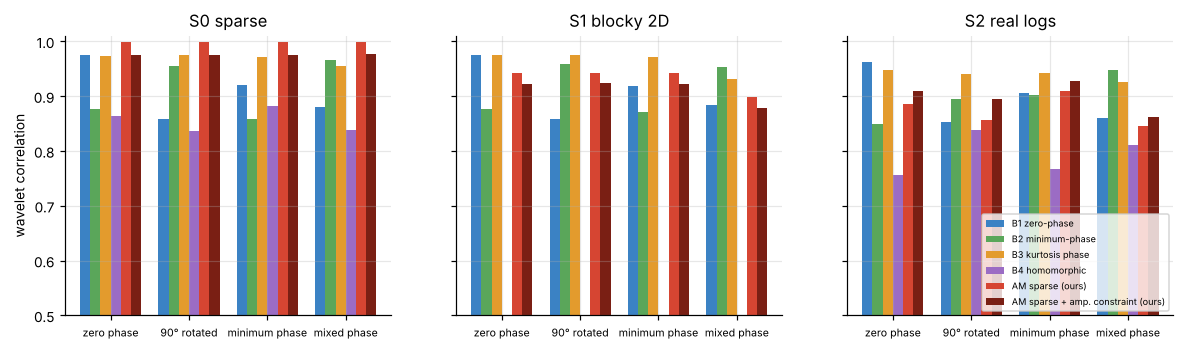

In [20]:
pivot = main[main.method != "oracle"].groupby(["testbed", "wavelet", "method"]).wavelet_corr.mean().unstack("method")[order[1:]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, tb in zip(axes, TESTBEDS):
    sub = pivot.loc[tb].reindex(list(WAVELETS))
    xs = np.arange(len(sub))
    for i, m in enumerate(order[1:]):
        ax.bar(xs + (i - 2.5) * 0.13, sub[m], width=0.13, color=COL[m], label=NAMES[m])
    ax.set_xticks(xs); ax.set_xticklabels(sub.index, fontsize=7); ax.set_ylim(0.5, 1.01); ax.set_title(tb)
axes[0].set_ylabel("wavelet correlation"); axes[-1].legend(fontsize=6, loc="lower right")
savefig(fig, "10_main_wavelet_corr"); plt.show()

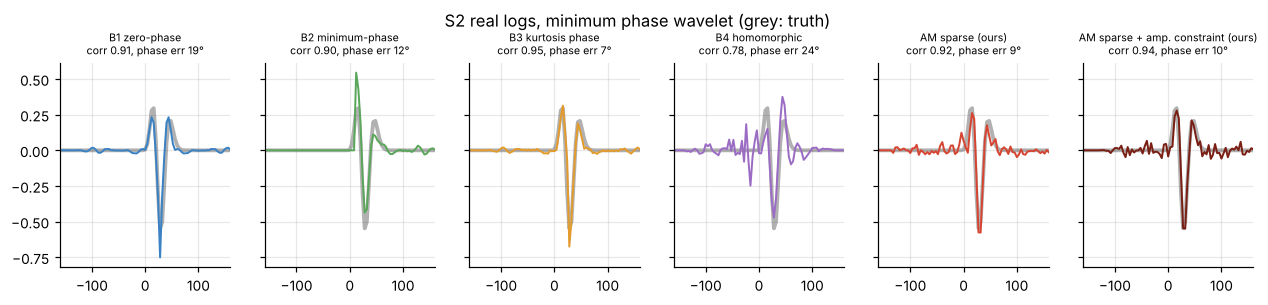

In [21]:
case_tb, case_w = "S2 real logs", "minimum phase"
y_ = add_noise(conv(TESTBEDS[case_tb], WAVELETS[case_w]), SNR_DB, np.random.default_rng(10))
est_case = estimate_all(y_)
fig, axes = plt.subplots(1, len(est_case), figsize=(14, 2.4), sharey=True)
for ax, (m, w_hat) in zip(axes, est_case.items()):
    c, s, sg = best_align(w_hat, WAVELETS[case_w])
    ax.plot(tt, WAVELETS[case_w], color=COL["truth"], lw=2.5, alpha=0.35)
    ax.plot(tt, sg * shift(w_hat, s), color=COL[m], lw=1.3)
    ax.set_title(f"{NAMES[m]}\ncorr {c:.2f}, phase err {abs(phase_error(w_hat, WAVELETS[case_w])):.0f}°", fontsize=7)
    ax.set_xlim(-160, 160)
fig.suptitle(f"{case_tb}, {case_w} wavelet (grey: truth)", y=1.08)
savefig(fig, "11_wavelets_example"); plt.show()

**Reading the comparison.**

* On **S0** the model holds and AM matches the oracle (wavelet correlation 0.999, zero phase
  error, same spike F1) for **all four wavelets, including mixed phase**. Each baseline is right
  only when its phase assumption matches: B1 for zero phase, B2 near minimum phase, B3 for
  constant phase. B3 is the strongest baseline, but it cannot represent the mixed-phase wavelet.
* On **S1** AM is about 19° "wrong" for every wavelet. That is not noise: a half-sample delay at
  25 Hz is $0.002\ \text{s} \times 25\ \text{Hz} \times 360° = 18°$, exactly the delay of the
  two-sample ramp $g = [\tfrac12, \tfrac12]$. AM has found the effective wavelet $w * g$ (3e and
  Section 7.5). B3 cannot represent a fractional delay, so it stays near $w$ and scores best
  here. B4 breaks down on this data set: the homomorphic method is known to be fragile.
* On **S2** (real reflectivity, only 24 short windows of 0.8 s) every method loses accuracy and
  no method dominates. B3 has the best wavelet correlation; AM and AM-amp have phase errors
  similar to B3 but a worse amplitude spectrum. The blue colour of real reflectivity biases
  the amplitude spectrum for every method, and short windows make all statistics noisy.
  Reflectivity correlation is low for everyone, including the oracle, because real
  reflectivity is not sparse.

### 7.3 How does accuracy depend on the wavelet's phase?

Constant-phase rotations of the Ricker from $-90°$ to $90°$, on S0 and S2.

99 s


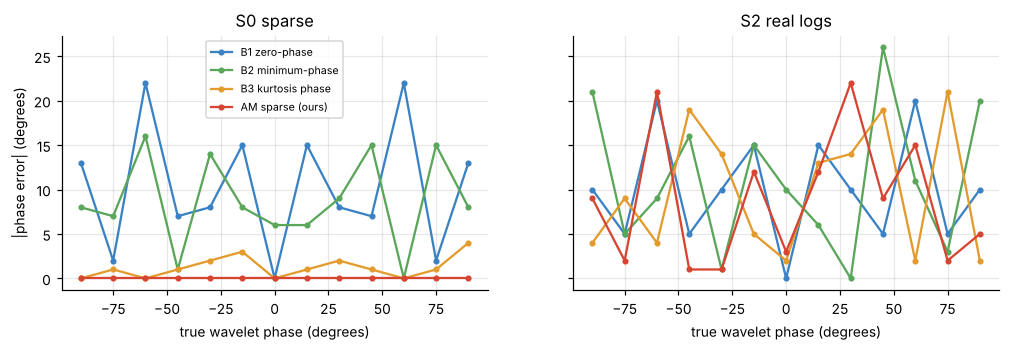

In [22]:
t0 = time.time()
rows = []
for tb in ["S0 sparse", "S2 real logs"]:
    for th in range(-90, 91, 15):
        w_ = unit(rotate_phase(ricker(25), th))
        y_ = add_noise(conv(TESTBEDS[tb], w_), SNR_DB, np.random.default_rng(200 + th))
        for m, w_hat in estimate_all(y_, which=("B1", "B2", "B3", "AM")).items():
            rows.append(dict(testbed=tb, theta=th, method=m, phase_err=abs(phase_error(w_hat, w_)),
                             wavelet_corr=best_align(w_hat, w_)[0]))
phase_sweep = pd.DataFrame(rows); phase_sweep.to_csv(f"{RES}/phase_sweep.csv", index=False)
print(f"{time.time() - t0:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, tb in zip(axes, ["S0 sparse", "S2 real logs"]):
    for m in ["B1", "B2", "B3", "AM"]:
        q = phase_sweep[(phase_sweep.testbed == tb) & (phase_sweep.method == m)]
        ax.plot(q.theta, q.phase_err, "o-", ms=3, color=COL[m], label=NAMES[m])
    ax.set_title(tb); ax.set_xlabel("true wavelet phase (degrees)")
axes[0].set_ylabel("|phase error| (degrees)"); axes[0].legend(fontsize=7)
savefig(fig, "12_phase_sweep"); plt.show()

**Reading the phase sweep.** On S0, AM has zero phase error for every rotation. B1 is right only
near 0°, B2 is erratic (a constant-phase wavelet is not minimum phase), and B3 stays within a
few degrees because a constant rotation is exactly what it searches over. On S2 (24 short
windows of real reflectivity) every method scatters between 0° and about 25° with no consistent
winner: there is simply not enough data to fix the phase better than that.

### 7.4 What does "multichannel" buy? And how much noise is too much?

Left: number of traces $J$ on S0 with a 60° wavelet (3 seeds). Right: noise level on S0 and S2.

131 s


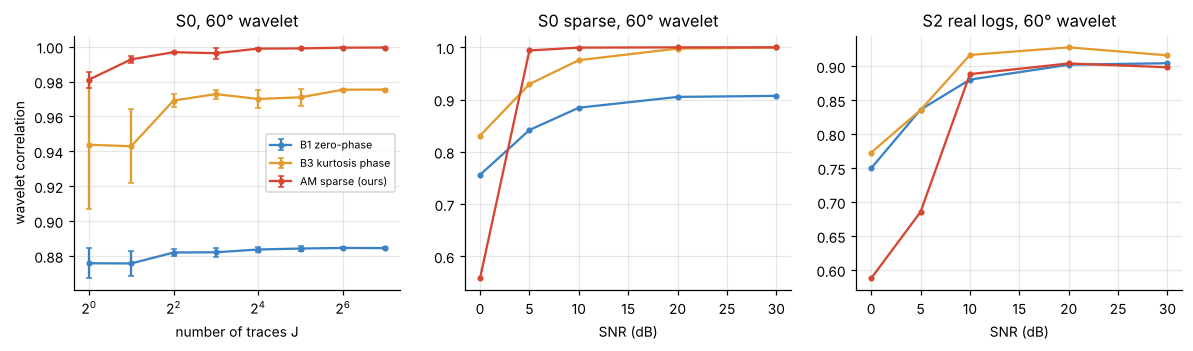

In [23]:
t0 = time.time()
rows = []
w_ = unit(rotate_phase(ricker(25), 60))
for J in [1, 2, 4, 8, 16, 32, 64, 128]:
    for seed in range(3):
        R_ = make_S0(J=J, seed=200 + seed)
        y_ = add_noise(conv(R_, w_), SNR_DB, np.random.default_rng(300 + seed))
        for m, w_hat in estimate_all(y_, which=("B1", "B3", "AM")).items():
            rows.append(dict(J=J, seed=seed, method=m, phase_err=abs(phase_error(w_hat, w_)), wavelet_corr=best_align(w_hat, w_)[0]))
j_sweep = pd.DataFrame(rows)
rows = []
for tb in ["S0 sparse", "S2 real logs"]:
    for snr in [0, 5, 10, 20, 30]:
        for seed in range(2):
            y_ = add_noise(conv(TESTBEDS[tb], w_), snr, np.random.default_rng(400 + seed))
            for m, w_hat in estimate_all(y_, which=("B1", "B3", "AM")).items():
                rows.append(dict(testbed=tb, snr=snr, seed=seed, method=m, phase_err=abs(phase_error(w_hat, w_)), wavelet_corr=best_align(w_hat, w_)[0]))
snr_sweep = pd.DataFrame(rows)
j_sweep.to_csv(f"{RES}/traces_sweep.csv", index=False); snr_sweep.to_csv(f"{RES}/noise_sweep.csv", index=False)
print(f"{time.time() - t0:.0f} s")
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for m in ["B1", "B3", "AM"]:
    q = j_sweep[j_sweep.method == m].groupby("J").wavelet_corr.agg(["mean", "std"])
    axes[0].errorbar(q.index, q["mean"], q["std"], marker="o", ms=3, capsize=2, color=COL[m], label=NAMES[m])
    for ax, tb in zip(axes[1:], ["S0 sparse", "S2 real logs"]):
        q = snr_sweep[(snr_sweep.method == m) & (snr_sweep.testbed == tb)].groupby("snr").wavelet_corr.mean()
        ax.plot(q.index, q.values, "o-", ms=3, color=COL[m])
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("number of traces J"); axes[0].set_ylabel("wavelet correlation"); axes[0].legend(fontsize=7)
axes[0].set_title("S0, 60° wavelet")
for ax, tb in zip(axes[1:], ["S0 sparse", "S2 real logs"]):
    ax.set_xlabel("SNR (dB)"); ax.set_title(f"{tb}, 60° wavelet")
savefig(fig, "13_traces_and_noise"); plt.show()

**Reading the sweeps.**

* **Traces.** AM reaches a wavelet correlation of 0.98 from a *single* trace of 500 samples and
  0.997 from four. B3 levels off near 0.975: it only rotates the B1 amplitude spectrum, so its
  accuracy is capped by that spectrum. B1 stays near 0.88 because its phase is wrong.
* **Noise.** On S0, AM is the best method from 5 dB upward (tied with B3 at 20 to 30 dB) but
  **collapses at 0 dB** (0.56), where the baselines degrade gracefully: when noise is as strong
  as signal, the sparse codes start fitting noise and the wavelet step follows them. On S2, B3
  is best (or tied) at every noise level; AM stays within about 0.03 of it from 10 dB up.

### 7.5 Where does identifiability end? Sparsity and shared filters

**Sparsity sweep.** Bernoulli($p$)-Laplace reflectivity from very sparse ($p = 1\%$) to dense
($p = 100\%$, i.i.d. Laplace), plus i.i.d. Gaussian. By 3b phase should become unrecoverable as
the reflectivity approaches Gaussian. Kurtosis of each reflectivity is shown on the top axis.

**Shared filter on S1.** Score AM against the true wavelet $w$ and against the effective
wavelet $w * g$ with $g = [\tfrac12, \tfrac12]$ (Section 4.2).

157 s


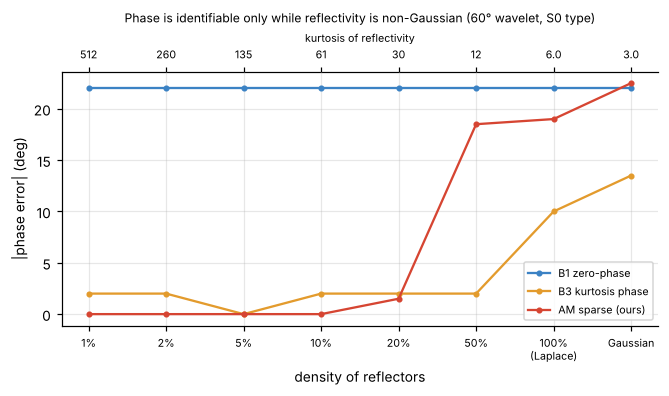

,corr_vs_true,corr_vs_effective
wavelet,,
90° rotated,0.942,0.999
minimum phase,0.943,0.999
mixed phase,0.899,0.999
zero phase,0.942,0.999


In [24]:
t0 = time.time()
rows = []
dens = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, "gauss"]
for p in dens:
    for seed in range(2):
        g_ = np.random.default_rng(500 + seed)
        R_ = g_.standard_normal((100, 500)) if p == "gauss" else g_.laplace(size=(100, 500)) * (g_.random((100, 500)) < p)
        y_ = add_noise(conv(R_, w_), SNR_DB, np.random.default_rng(600 + seed))
        for m, w_hat in estimate_all(y_, which=("B1", "B3", "AM")).items():
            rows.append(dict(density=str(p), kurtosis=kurt(R_), seed=seed, method=m, phase_err=abs(phase_error(w_hat, w_)), wavelet_corr=best_align(w_hat, w_)[0]))
dens_sweep = pd.DataFrame(rows); dens_sweep.to_csv(f"{RES}/sparsity_sweep.csv", index=False)

rows = []
for wn, wt in WAVELETS.items():
    w_eff = unit(np.convolve(wt, [0.5, 0.5])[:L])
    for seed in range(2):
        y_ = add_noise(conv(S1_R, wt), SNR_DB, np.random.default_rng(10 + seed))
        w_hat = blind_am(y_)[0]
        rows.append(dict(wavelet=wn, seed=seed, corr_vs_true=best_align(w_hat, wt)[0], corr_vs_effective=best_align(w_hat, w_eff)[0]))
gauge_table = pd.DataFrame(rows).groupby("wavelet")[["corr_vs_true", "corr_vs_effective"]].mean().round(3)
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 3))
labels = [str(p) for p in dens]
for m in ["B1", "B3", "AM"]:
    q = dens_sweep[dens_sweep.method == m].groupby("density", sort=False).phase_err.mean().reindex(labels)
    ax.plot(range(len(labels)), q.values, "o-", ms=3, color=COL[m], label=NAMES[m])
kq = dens_sweep.groupby("density", sort=False).kurtosis.mean().reindex(labels)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(["1%", "2%", "5%", "10%", "20%", "50%", "100%\n(Laplace)", "Gaussian"], fontsize=7)
ax2 = ax.secondary_xaxis("top"); ax2.set_xticks(range(len(labels))); ax2.set_xticklabels([f"{k:.0f}" if k > 10 else f"{k:.1f}" for k in kq.values], fontsize=7)
ax2.set_xlabel("kurtosis of reflectivity", fontsize=7)
ax.set_xlabel("density of reflectors"); ax.set_ylabel("|phase error| (deg)"); ax.legend(fontsize=7)
ax.set_title("Phase is identifiable only while reflectivity is non-Gaussian (60° wavelet, S0 type)", fontsize=8)
savefig(fig, "14_sparsity_sweep"); plt.show()
gauge_table

**Reading the identifiability tests.**

* **Sparsity.** AM is exact up to 20% reflector density (kurtosis about 30 and above) and then
  breaks down to about 19° error once kurtosis drops to 12 or below. B3 holds on until the
  reflectivity is dense Laplace (kurtosis 6). So the $\ell_1$ model needs genuine sparsity,
  while kurtosis only needs non-Gaussianity. The six wells have kurtosis between about 7 and 33
  (Section 4.1): real reflectivity sits right at AM's boundary, which explains the S2 results.
* **Shared filter.** On S1, AM's wavelet correlates 0.90 to 0.94 with the true wavelet but
  **0.999 with the effective wavelet $w * g$** for all four wavelets. The method is doing
  exactly what the data allow (3e). The "error" is a filter that no trace-only method can
  assign to the Earth rather than the wavelet.

### 7.6 Thin beds: why the phase matters

Two reflectors $d$ samples apart (strengths 1 and $\pm 0.8$), 25 Hz zero-phase wavelet, SNR
20 dB, 10 noise draws per case. A pair counts as **cleanly resolved** if the two largest output
peaks fall within $\pm 1$ sample of the true positions with the right signs **and** no other
peak exceeds 30% of the maximum (false spikes are what a wrong wavelet produces).

Compared: ridge-regularised least squares (Wiener-type) with the true wavelet, and $\ell_1$
($\rho = 0.1$) with the true wavelet or with the right amplitude spectrum but a 15° or 30° phase
error.

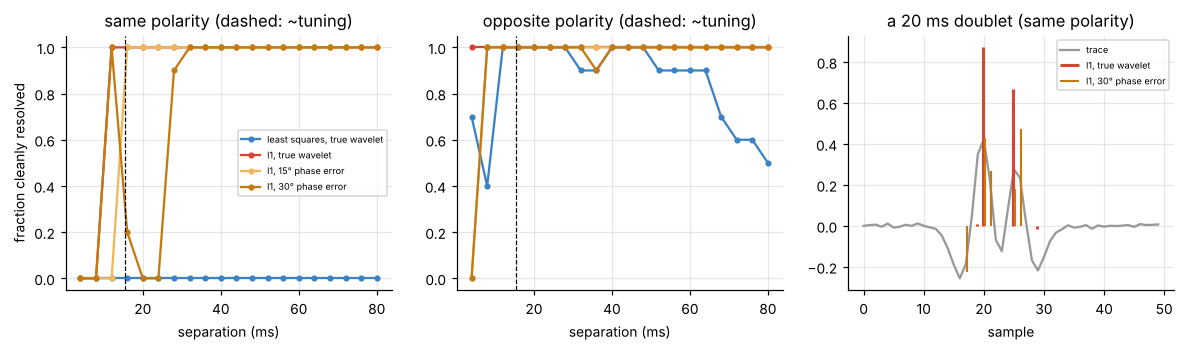

method           l1, 15° phase error  l1, 30° phase error  l1, true wavelet  \
polarity sep_ms                                                               
opposite 4.0                     0.0                  0.0               1.0   
         8.0                     1.0                  1.0               1.0   
         12.0                    1.0                  1.0               1.0   
         16.0                    1.0                  1.0               1.0   
         20.0                    1.0                  1.0               1.0   
         24.0                    1.0                  1.0               1.0   
         40.0                    1.0                  1.0               1.0   
same     4.0                     0.0                  0.0               0.0   
         8.0                     0.0                  0.0               0.0   
         12.0                    0.0                  1.0               1.0   
         16.0                    1.0                  0.2               1.0   
         20.0                    1.0                  0.0               1.0   
         24.0                    1.0                  0.0               1.0   
         40.0                    1.0                  1.0               1.0   

method           least squares, true wavelet  
polarity sep_ms                               
opposite 4.0                             0.7  
         8.0                             0.4  
         12.0                            1.0  
         16.0                            1.0  
         20.0                            1.0  
         24.0                            1.0  
         40.0                            1.0  
same     4.0                             0.0  
         8.0                             0.0  
         12.0                            0.0  
         16.0                            0.0  
         20.0                            0.0  
         24.0                            0.0  
         40.0                            0.0

In [25]:
def peaks_by_size(x):
    pk, _ = signal.find_peaks(np.abs(x))
    return pk[np.argsort(-np.abs(x[pk]))]

def resolved(x, p1, p2, pol, clean=0.3):
    pk = peaks_by_size(x)
    if len(pk) < 2:
        return False
    a, b = np.sort(pk[:2])
    ok = abs(a - p1) <= 1 and abs(b - p2) <= 1 and np.sign(x[a]) == 1 and np.sign(x[b]) == pol
    others = [q for q in pk if abs(q - a) > 1 and abs(q - b) > 1]
    return ok and (not others or np.abs(x[others]).max() < clean * np.abs(x).max())

w_t = WAVELETS["zero phase"]
Hw = np.array([conv(e[None], w_t)[0] for e in np.eye(200)]).T
deconvolvers = {
    "least squares, true wavelet": lambda y_: np.linalg.solve(Hw.T @ Hw + 0.05 * np.eye(200), Hw.T @ y_[0]),
    "l1, true wavelet": lambda y_: fista(y_, w_t, 0.1 * lam_max(y_, w_t), 400)[0],
}
for th in (15, 30):
    w_b = unit(rotate_phase(w_t, th))
    deconvolvers[f"l1, {th}° phase error"] = (lambda wb: (lambda y_: fista(y_, wb, 0.1 * lam_max(y_, wb), 400)[0]))(w_b)
rows = []
for pol in [+1, -1]:
    for dsep in range(1, 21):
        hits = dict.fromkeys(deconvolvers, 0)
        for seed in range(10):
            r_ = np.zeros(200); r_[90] = 1; r_[90 + dsep] = pol * 0.8
            y_ = add_noise(conv(r_[None], w_t), 20, np.random.default_rng(seed))
            for k_, f_ in deconvolvers.items():
                hits[k_] += resolved(f_(y_), 90, 90 + dsep, pol)
        for k_, v_ in hits.items():
            rows.append(dict(polarity="same" if pol > 0 else "opposite", sep_ms=dsep * DT * 1000, method=k_, resolved=v_ / 10))
wedge = pd.DataFrame(rows); wedge.to_csv(f"{RES}/thin_bed.csv", index=False)
wcol = dict(zip(deconvolvers, ["#3b82c4", "#d64532", "#f0b85a", "#c47a12"]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, pol in zip(axes[:2], ["same", "opposite"]):
    for mth in deconvolvers:
        q = wedge[(wedge.polarity == pol) & (wedge.method == mth)]
        ax.plot(q.sep_ms, q.resolved, "o-", ms=3, color=wcol[mth], label=mth)
    ax.axvline(1000 / (2.6 * 25), color="k", ls="--", lw=0.8)
    ax.set_xlabel("separation (ms)"); ax.set_title(f"{pol} polarity (dashed: ~tuning)"); ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("fraction cleanly resolved"); axes[0].legend(fontsize=6)
r_ = np.zeros(200); r_[90] = 1; r_[95] = 0.8
y_ = add_noise(conv(r_[None], w_t), 20, np.random.default_rng(0))
sl_ = slice(70, 120)
axes[2].plot(np.arange(50), y_[0][sl_], color="#999999", label="trace")
axes[2].vlines(np.arange(50) - 0.15, 0, deconvolvers["l1, true wavelet"](y_)[sl_], color="#d64532", lw=2, label="l1, true wavelet")
axes[2].vlines(np.arange(50) + 0.15, 0, deconvolvers["l1, 30° phase error"](y_)[sl_], color="#c47a12", lw=1.4, label="l1, 30° phase error")
axes[2].set_title("a 20 ms doublet (same polarity)"); axes[2].legend(fontsize=6); axes[2].set_xlabel("sample")
savefig(fig, "15_thin_beds"); plt.show()
wedge.pivot_table(index=["polarity", "sep_ms"], columns="method", values="resolved").loc[(slice(None), [4.0, 8.0, 12.0, 16.0, 20.0, 24.0, 40.0]), :]

**Reading the thin-bed test.** Least squares never gives a clean same-polarity doublet: its
side lobes count as false spikes. With the true wavelet, $\ell_1$ separates same-polarity
pairs from 12 ms, below the tuning thickness. With a 30° phase error it fails in the 16 to 24 ms
range, right around tuning, by adding false spikes. Opposite-polarity pairs are easier for
every method (least squares still loses some at larger separations, where its side lobes
count as false spikes). So the phase is not cosmetic: a phase error of a few tens of degrees removes
exactly the extra resolution that sparse deconvolution is used for.

## 8. Field data: Penobscot crossline 1155

### 8.1 A reference wavelet from the well

At the well we know the reflectivity (from the logs), so the wavelet can be estimated by least
squares, with the wavelet step of Section 5.2 applied to traces near the well. To keep the
comparison fair the reference is fitted on traces 2 to 6 positions from the well on each side
and **scored at the well trace**, which it never saw. This "well wavelet" is a reference, not
the truth: it inherits errors from the depth-to-time conversion and assumes flat layers near
the well. Its length is 200 ms with moderate damping: longer least-squares wavelets fit
nearby traces slightly better (tie 0.65 at 320 ms against 0.58 at 200 ms) but ring, because
they absorb the time misalignment left by a bulk-shift-only tie.

In [26]:
near = [j_well + k for k in (-6, -5, -4, -3, -2, 2, 3, 4, 5, 6)]
L_WELL = 51                                    # 200 ms; longer wavelets ring (see text)
w_well = wavelet_ls(Y_field[near], np.tile(r_well, (len(near), 1)), L_WELL, ridge=1.0) * signal.windows.tukey(L_WELL, 0.3)
w_well = unit(np.pad(w_well, ((L - L_WELL) // 2, (L - L_WELL) // 2)))

def const_phase(w):
    """Constant phase angle of w relative to the zero-phase wavelet with its amplitude spectrum, in (-90, 90]."""
    z = from_spectrum(np.abs(spectrum_of(w)), len(w))
    th = np.arange(-90, 90)
    sc = [best_align(w, rotate_phase(z, t), 20)[0] for t in th]
    return int(th[int(np.argmax(sc))])

def tie_corr(w, j=j_well, max_shift=8):
    syn = conv(r_well[None], w)[0]
    return max(abs(ncorr(shift(syn, s), Y_field[j])) for s in range(-max_shift, max_shift + 1))

print(f"well wavelet: constant phase {const_phase(w_well)}°, tie correlation at the well trace {tie_corr(w_well):.2f}")

# How stable is the reference? Refit it with other lengths and damping.
sens = []
for Lw_ in (41, 51, 61, 81):
    for rg_ in (0.1, 1.0):
        w_ = wavelet_ls(Y_field[near], np.tile(r_well, (len(near), 1)), Lw_, ridge=rg_) * signal.windows.tukey(Lw_, 0.3)
        w_ = unit(np.pad(w_, ((L - Lw_) // 2, (L - Lw_) // 2)))
        sens.append(dict(length_ms=Lw_ * DT * 1000, ridge=rg_, constant_phase_deg=const_phase(w_), tie_corr_at_well=round(tie_corr(w_), 3)))
well_sensitivity = pd.DataFrame(sens)
well_sensitivity.to_csv(f"{RES}/well_wavelet_sensitivity.csv", index=False)
well_sensitivity

well wavelet: constant phase -44°, tie correlation at the well trace 0.58


,length_ms,ridge,constant_phase_deg,tie_corr_at_well
0,164.0,0.1,25,0.589
1,164.0,1.0,-45,0.567
2,204.0,0.1,28,0.603
3,204.0,1.0,-44,0.575
4,244.0,0.1,30,0.620
5,244.0,1.0,-44,0.585
6,324.0,0.1,29,0.651
7,324.0,1.0,-45,0.617


**The reference phase is not stable.** The well wavelet's constant phase is about $+28°$ with
light damping and about $-44°$ with heavier damping, whatever its length, while the tie
correlation changes only a little. With one well, a bulk-shift tie and an 1.8 s window, the
data do not pin the phase down better than roughly $\pm 35°$. Keep that in mind when reading
the comparison below: tie correlation is a usable score, but phase agreement with the well is
not.

### 8.2 Blind estimates from all 401 traces, with a bootstrap for AM

Every method sees all 401 traces in the window and nothing from the well. For AM, the traces
are also resampled with replacement 6 times (200 traces each) to get a spread of estimates.

In [27]:
t0 = time.time()
est_field = estimate_all(Y_field)
boot = []
g_ = np.random.default_rng(7)
for b in range(6):
    pick = g_.choice(Y_field.shape[0], 200, replace=True)
    boot.append(blind_am(Y_field[pick])[0])
print(f"{time.time() - t0:.0f} s")
rows = []
for m, w_hat in est_field.items():
    rows.append(dict(method=NAMES[m], corr_to_well_wavelet=best_align(w_hat, w_well, 25)[0],
                     constant_phase_deg=const_phase(w_hat), tie_corr_at_well=tie_corr(w_hat)))
rows.append(dict(method="well wavelet (reference)", corr_to_well_wavelet=1.0, constant_phase_deg=const_phase(w_well), tie_corr_at_well=tie_corr(w_well)))
field_table = pd.DataFrame(rows).set_index("method").round(2)
boot_phase = [const_phase(w) for w in boot]
print("AM bootstrap: constant phase", boot_phase, f"| corr to well wavelet {np.mean([best_align(w, w_well, 25)[0] for w in boot]):.2f} ± {np.std([best_align(w, w_well, 25)[0] for w in boot]):.2f}")
field_table.to_csv(f"{RES}/field_comparison.csv")
field_table

118 s


AM bootstrap: constant phase [10, 10, 10, 10, 13, 6] | corr to well wavelet 0.74 ± 0.00


,corr_to_well_wavelet,constant_phase_deg,tie_corr_at_well
method,,,
B1 zero-phase,0.80,0,0.46
B2 minimum-phase,0.74,-90,0.42
B3 kurtosis phase,0.78,-14,0.44
B4 homomorphic,0.68,29,0.35
AM sparse (ours),0.75,11,0.39
AM sparse + amp. constraint (ours),0.82,3,0.45
well wavelet (reference),1.00,-44,0.58


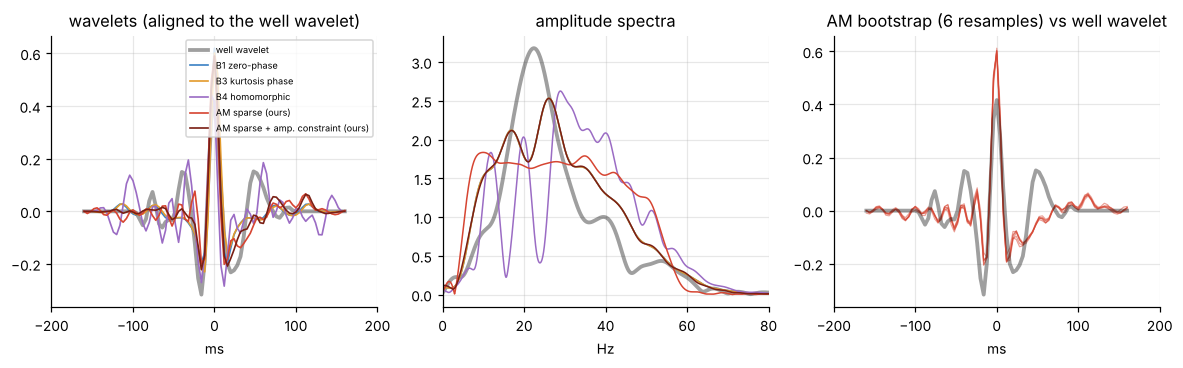

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
f = np.fft.rfftfreq(4096, DT)
axes[0].plot(tt, w_well, color=COL["well"], lw=2.5, alpha=0.4, label="well wavelet")
axes[1].plot(f, np.abs(spectrum_of(w_well)), color=COL["well"], lw=2.5, alpha=0.4)
for m in ["B1", "B3", "B4", "AM", "AM-amp"]:
    c, s, sg = best_align(est_field[m], w_well, 25)
    axes[0].plot(tt, sg * shift(est_field[m], s), color=COL[m], lw=1.1, label=NAMES[m])
    axes[1].plot(f, np.abs(spectrum_of(est_field[m])), color=COL[m], lw=1)
for w_b in boot:
    c, s, sg = best_align(w_b, w_well, 25)
    axes[2].plot(tt, sg * shift(w_b, s), color=COL["AM"], lw=0.8, alpha=0.5)
axes[2].plot(tt, w_well, color=COL["well"], lw=2.5, alpha=0.4)
axes[0].set_xlim(-200, 200); axes[0].legend(fontsize=6); axes[0].set_title("wavelets (aligned to the well wavelet)"); axes[0].set_xlabel("ms")
axes[1].set_xlim(0, 80); axes[1].set_title("amplitude spectra"); axes[1].set_xlabel("Hz")
axes[2].set_xlim(-200, 200); axes[2].set_title("AM bootstrap (6 resamples) vs well wavelet"); axes[2].set_xlabel("ms")
savefig(fig, "16_field_wavelets"); plt.show()

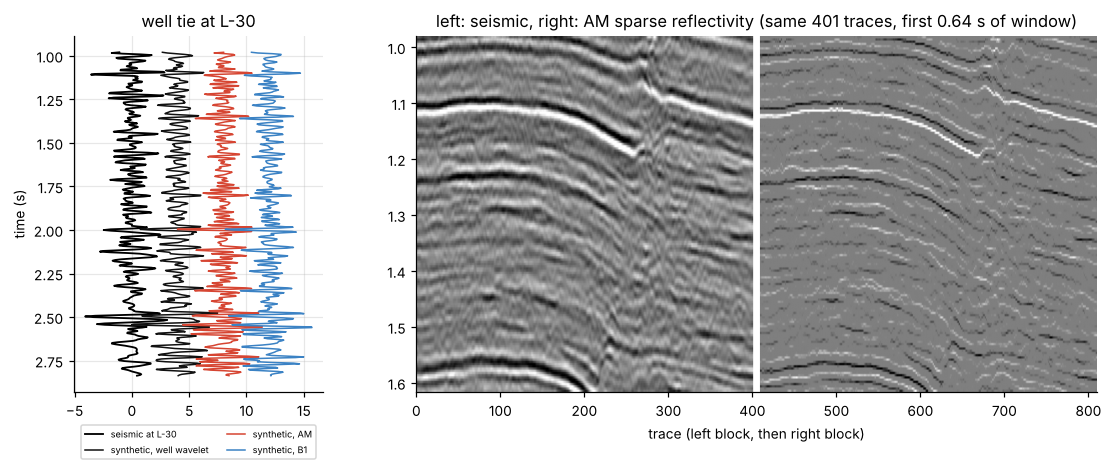

In [29]:
tw = np.arange(len(r_well)) * DT + win.start * DT
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.1, 3]))
ax = axes[0]
ax.plot(Y_field[j_well], tw, "k", lw=1.2, label="seismic at L-30")
for i_, (lab, w_hat, c) in enumerate([("well wavelet", w_well, COL["well"]), ("AM", est_field["AM"], COL["AM"]), ("B1", est_field["B1"], COL["B1"])]):
    syn = conv(r_well[None], w_hat)[0]
    s_best = max(range(-8, 9), key=lambda s: abs(ncorr(shift(syn, s), Y_field[j_well])))
    syn = shift(syn, s_best); syn *= np.sign(ncorr(syn, Y_field[j_well])) * np.std(Y_field[j_well]) / np.std(syn)
    ax.plot(syn + 4 * (i_ + 1), tw, color=c, lw=1, label=f"synthetic, {lab}")
ax.invert_yaxis(); ax.set_ylabel("time (s)"); ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2); ax.set_title("well tie at L-30")
x_field = fista(Y_field, est_field["AM"], 0.05 * lam_max(Y_field, est_field["AM"]), 300)
sl = slice(0, 160)
vm1, vm2 = np.percentile(np.abs(Y_field), 99), np.percentile(np.abs(x_field), 99.5)
both = np.concatenate([Y_field[:, sl] / vm1, np.full((8, sl.stop), np.nan), x_field[:, sl] / vm2])
axes[1].imshow(both.T, aspect="auto", cmap="gray_r", vmin=-1, vmax=1, extent=[0, both.shape[0], tw[sl.stop - 1], tw[0]])
axes[1].set_title("left: seismic, right: AM sparse reflectivity (same 401 traces, first 0.64 s of window)")
axes[1].set_xlabel("trace (left block, then right block)"); axes[1].grid(False)
savefig(fig, "17_field_tie_and_section"); plt.show()

**Reading the field results.**

* The blind methods **agree with each other** on a phase close to zero: B1 0° (by
  construction), B3 $-14°$, AM-amp $3°$, AM $11°$ (bootstrap 6° to 13°), B4 $29°$. The AM
  bootstrap spread is small, so AM's estimate is stable with respect to which traces are used.
* Against the well reference, **AM-amp is closest in shape** (correlation 0.82, then B1 0.80,
  B3 0.78, AM 0.75). For tie quality B1 (0.46), AM-amp (0.45) and B3 (0.44) are close; plain AM
  is lower (0.39) and the well's own wavelet reaches 0.58. Plain AM learns a broader, flatter
  amplitude spectrum than the others (middle panel): with real, non-sparse reflectivity the
  $\ell_1$ codes leave some of the reflectivity's structure to the wavelet (3e). Constraining
  the amplitude spectrum removes most of that and keeps the sparse phase estimate.
* Because the reference phase itself moves by about 70° with a damping choice (8.1), this line
  cannot rank the methods by phase. It does show that AM-amp is as good as the best classical
  method on real data, and that plain AM needs the amplitude constraint there.
* The sparse section (right panel) keeps the main horizons and the fault, and sharpens the
  events, as expected from deconvolution.

## 9. Summary

The cell below prints the main numbers from this run, read from the result tables, so the text
can be checked against what was actually computed.

In [30]:
print("Main comparison (mean over 4 wavelets x 2 seeds):")
print(summary_main.to_string())
print("\nShared-filter gauge on S1 (AM):")
print(gauge_table.to_string())
print("\nSparsity sweep, |phase error| (deg):")
print(dens_sweep.groupby(["density", "method"], sort=False).phase_err.mean().unstack().round(1).reindex([str(p) for p in dens]).to_string())
print("\nTraces sweep, wavelet corr (mean):")
print(j_sweep.groupby(["J", "method"]).wavelet_corr.mean().unstack().round(3).to_string())
print("\nField:")
print(field_table.to_string())
print("AM bootstrap constant phase:", boot_phase)
json.dump(dict(summary_main=summary_main.reset_index().to_dict("records"),
               field=field_table.reset_index().to_dict("records"), boot_phase=boot_phase,
               gauge=gauge_table.reset_index().to_dict("records")),
          open(f"{RES}/summary.json", "w"), indent=1, default=float)

Main comparison (mean over 4 wavelets x 2 seeds):
                     wavelet_corr  phase_err  spike_f1  refl_corr
testbed      method                                              
S0 sparse    oracle         1.000      0.000     0.836      0.945
             B1             0.908     14.000     0.558      0.694
             B2             0.913     10.625     0.529      0.687
             B3             0.969      4.250     0.634      0.849
             B4             0.855      9.375     0.426      0.529
             AM             0.999      0.000     0.832      0.944
             AM-amp         0.976      1.625     0.662      0.871
S1 blocky 2D oracle         1.000      0.000     0.789      0.952
             B1             0.909     14.000     0.630      0.788
             B2             0.915      8.250     0.612      0.779
             B3             0.963      5.000     0.747      0.919
             B4             0.178     28.375     0.222      0.207
             AM           

### What to take from this notebook

(Numbers are in the printed summary above; the points below are written against them.)

**On the method**

* The operator view is exact and cheap: an adjoint test, FFT convolutions, the exact
  Lipschitz constant $\max_f |W(f)|^2$ in one FFT, and a wavelet step that is a small Toeplitz
  solve. Alternating minimisation with $\lambda$ continuation converges in about 10 outer
  iterations and a few seconds.
* **When reflectivity is sparse, AM is as good as the oracle**: wavelet correlation 0.999 and
  zero phase error for zero-, constant-, minimum- and mixed-phase wavelets, from as little as
  one trace (0.98). Every classical baseline is right only when its phase assumption matches
  the wavelet; none handles mixed phase.
* **AM has two clear limits.** It needs real sparsity: it breaks down once reflector density
  passes about 20% (kurtosis about 12 or below), while kurtosis-based phase estimation (B3)
  survives down to dense Laplace reflectivity. And it collapses at 0 dB SNR, where the
  baselines degrade gracefully.
* **Identifiability.** Any filter shared by all traces moves into the wavelet. On the blocky
  model AM recovers the effective wavelet $w * g$ with correlation 0.999; its apparent 19° phase
  error is exactly the half-sample delay of the ramped interfaces. This is the seismic version
  of the shared-support problem in the rainfall notebook.
* **Phase matters for thin beds**: with the true wavelet, $\ell_1$ deconvolution separates
  same-polarity reflectors from 12 ms, below tuning; a 30° phase error breaks it between 16 and
  24 ms.

**On real reflectivity and field data**

* Well-log reflectivity from six wells is heavy-tailed (kurtosis about 7 to 33), blue, and not
  strictly sparse. That puts it right at AM's sparsity boundary, which is why on the
  real-reflectivity test bed no method dominates and B3 is slightly ahead.
* On the Penobscot line, AM with the amplitude constraint (AM-amp) matches the best classical
  method: closest to the well wavelet in shape (0.82) and a tie correlation of 0.45 against 0.46
  for the best baseline. Plain AM needs that constraint on real data. The single well cannot
  validate phase: its own wavelet's phase moves by about 70° with the damping choice.

**What is new here, as far as this notebook goes** (a literature check is still needed):
a direct test of *which* wavelet a blind method can identify (the effective wavelet $w*g$,
not $w$), a sparsity-boundary map for $\ell_1$ against kurtosis phase estimation, and a field
comparison that reports the uncertainty of the well reference instead of treating it as truth.

### Next steps

* **Lateral coupling.** AM shares the wavelet across traces but treats each trace's
  reflectivity independently. Layers are continuous, so a group or structure-aware penalty
  across neighbouring traces is the natural next step (the multichannel deconvolution line of
  work in Sacchi's group).
* **Time-varying wavelet.** Attenuation changes the wavelet with depth. Several kernels with
  shared support, one per time window, is the DUNL multi-kernel setting, with the
  identifiability questions from the rainfall notebook.
* **Uncertainty.** The bootstrap gives a first spread. A posterior over the wavelet's phase
  (for example by sampling, or by comparing with diffusion posterior sampling) would say how
  much a field phase estimate can be trusted.
* **Heavier-tailed priors.** Cauchy or $\ell_p$ ($p<1$) priors match the real reflectivity
  statistics of Section 4.1 more closely than $\ell_1$.